# Actividad individual 6 · Redes neuronales en código
## Caso ViniAnalytics: clasificación del cultivar de un vino con un perceptrón multicapa (MLP)


---

### Contexto y pregunta de negocio
ViniAnalytics analiza muestras de vino en laboratorio. Cada muestra tiene **13 mediciones químicas** (alcohol, ácido málico, fenoles, flavonoides, intensidad de color, prolina, etc.), la **clase conocida** del vino (`target`: 0, 1 o 2, que corresponde a tres cultivares de la misma región) y un índice de calidad `QualyScore`.

**Pregunta de negocio:** ¿se puede identificar automáticamente el cultivar de un vino a partir de su análisis químico, con un desempeño suficiente para usar el modelo como *primer filtro* de verificación de etiquetado/origen antes de la revisión del enólogo?

**Tipo de problema:** clasificación supervisada **multiclase** (3 clases) → igual que el ejercicio Iris/Floralia visto en clase, y con la lógica de evaluación de errores del caso Metalmex.

### Metodología: CRISP-DM
1. Comprensión del negocio · 2. Comprensión de los datos (EDA) · 3. Preparación · 4. Modelado (diseño y entrenamiento del MLP) · 5. Evaluación · 6. Despliegue (recomendaciones).

> **Para ejecutar en Google Colab:** sube `wine_qualyscore.csv` al panel de archivos (o a la misma carpeta del notebook) y ejecuta todas las celdas en orden.

## 0. Librerías y reproducibilidad

In [2]:
import os, json, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import tensorflow as tf
tf.get_logger().setLevel("ERROR")   # oculta avisos internos de TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, roc_auc_score, roc_curve, log_loss, f1_score)

SEMILLA = 2011                      # semilla fija para que la corrida sea reproducible
keras.utils.set_random_seed(SEMILLA)  # fija numpy, random y TensorFlow (igual que Metalmex)

os.makedirs("figs", exist_ok=True)
RESULTADOS = {}                     # aquí guardamos las cifras clave para el informe
NOMBRES = ["Cultivar 0", "Cultivar 1", "Cultivar 2"]
COLORES = ["#2563B0", "#C13A42", "#2F8F5B"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(f"figs/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

I0000 00:00:1794439522.608608   18780 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794439522.609097   18780 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794439523.506887   18780 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794439523.507158   18780 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 1. Comprensión de los datos (exploración preliminar)
### 1.1 Carga y estructura

In [3]:
df = pd.read_csv("wine_qualyscore.csv")
print("Dimensiones:", df.shape)
display(df.head())
df.info()

Dimensiones: (178, 15)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,QualyScore
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,22.277
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,20.604
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,22.974
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,28.225
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,17.426


<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [4]:
PREDICTORAS = [c for c in df.columns if c not in ("target", "QualyScore")]
OBJETIVO = "target"
print(f"{len(PREDICTORAS)} predictoras:", PREDICTORAS)

display(df.describe().T.round(3))

13 predictoras: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.030,12.362,13.050,13.678,14.830
malic_acid,178.0,2.336,1.117,0.740,1.602,1.865,3.082,5.800
ash,178.0,2.367,0.274,1.360,2.210,2.360,2.558,3.230
alcalinity_of_ash,178.0,19.495,3.340,10.600,17.200,19.500,21.500,30.000
magnesium,178.0,99.742,14.282,70.000,88.000,98.000,107.000,162.000
total_phenols,178.0,2.295,0.626,0.980,1.742,2.355,2.800,3.880
flavanoids,178.0,2.029,0.999,0.340,1.205,2.135,2.875,5.080
nonflavanoid_phenols,178.0,0.362,0.124,0.130,0.270,0.340,0.438,0.660
proanthocyanins,178.0,1.591,0.572,0.410,1.250,1.555,1.950,3.580
color_intensity,178.0,5.058,2.318,1.280,3.220,4.690,6.200,13.000


### 1.2 Calidad de datos: valores faltantes, duplicados y tipos

In [5]:
calidad = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "% faltantes": (df.isna().mean() * 100).round(2),
    "valores únicos": df.nunique(),
    "tipo": df.dtypes.astype(str)
})
display(calidad)
print("Filas duplicadas:", df.duplicated().sum())
print("Columnas categóricas (object):", df.select_dtypes("object").columns.tolist())
RESULTADOS["n_filas"], RESULTADOS["n_columnas"] = df.shape
RESULTADOS["faltantes_total"] = int(df.isna().sum().sum())
RESULTADOS["duplicados"] = int(df.duplicated().sum())

,faltantes,% faltantes,valores únicos,tipo
alcohol,0,0.0,126,float64
malic_acid,0,0.0,133,float64
ash,0,0.0,79,float64
alcalinity_of_ash,0,0.0,63,float64
magnesium,0,0.0,53,float64
total_phenols,0,0.0,97,float64
flavanoids,0,0.0,132,float64
nonflavanoid_phenols,0,0.0,39,float64
proanthocyanins,0,0.0,101,float64
color_intensity,0,0.0,132,float64


Filas duplicadas: 0
Columnas categóricas (object): []


### 1.3 Distribución de la variable objetivo (balance de clases)

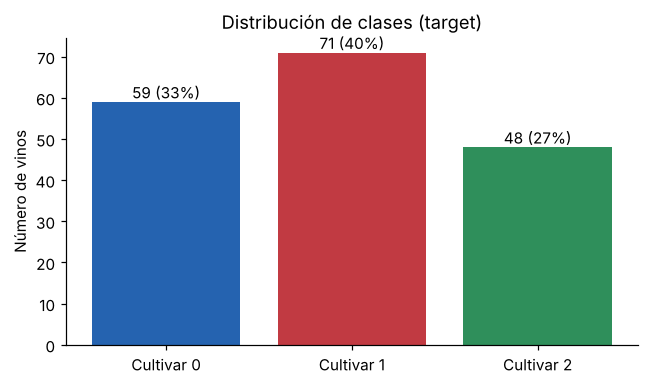

Razón clase mayor / clase menor: 1.48


In [6]:
conteo = df[OBJETIVO].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.6))
barras = ax.bar(NOMBRES, conteo.values, color=COLORES)
ax.bar_label(barras, labels=[f"{v} ({v/len(df):.0%})" for v in conteo.values])
ax.set(title="Distribución de clases (target)", ylabel="Número de vinos")
guardar("01_balance_clases")
RESULTADOS["conteo_clases"] = conteo.tolist()
print("Razón clase mayor / clase menor:", round(conteo.max() / conteo.min(), 2))

### 1.4 Distribuciones, escalas y valores atípicos

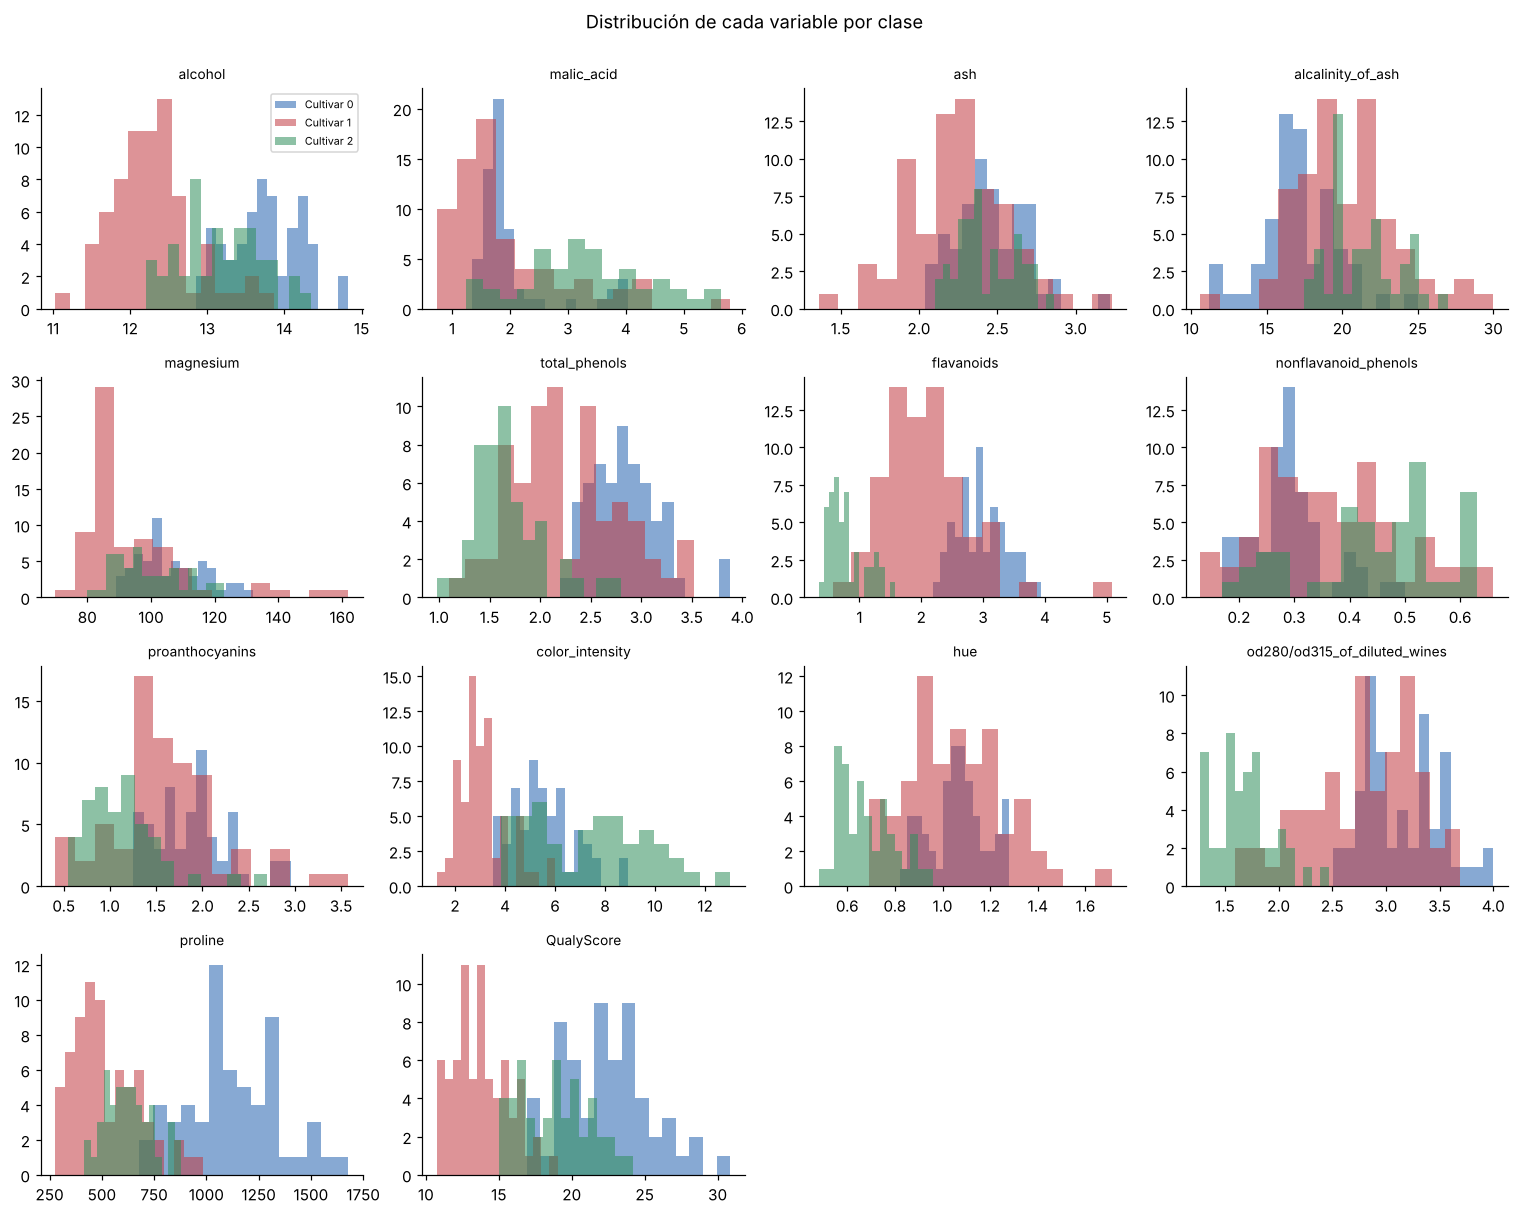

,min,max,std
proline,278.00,1680.00,314.907
magnesium,70.00,162.00,14.282
alcalinity_of_ash,10.60,30.00,3.340
color_intensity,1.28,13.00,2.318
malic_acid,0.74,5.80,1.117
flavanoids,0.34,5.08,0.999
alcohol,11.03,14.83,0.812
od280/od315_of_diluted_wines,1.27,4.00,0.710
total_phenols,0.98,3.88,0.626
proanthocyanins,0.41,3.58,0.572


,n atípicos (1.5·IQR)
malic_acid,3
ash,3
alcalinity_of_ash,4
magnesium,4
proanthocyanins,2
color_intensity,4
hue,1


Filas con al menos un atípico: 17


In [7]:
fig, ejes = plt.subplots(4, 4, figsize=(14, 11))
for ax, var in zip(ejes.ravel(), PREDICTORAS + ["QualyScore"]):
    for k in range(3):
        ax.hist(df.loc[df[OBJETIVO] == k, var], bins=15, alpha=.55, color=COLORES[k], label=NOMBRES[k])
    ax.set_title(var, fontsize=9)
for ax in ejes.ravel()[len(PREDICTORAS) + 1:]:
    ax.axis("off")
ejes[0, 0].legend(fontsize=7)
fig.suptitle("Distribución de cada variable por clase", y=1.0)
guardar("02_histogramas_por_clase")

# Diferencia de escalas: justifica la estandarización
escalas = df[PREDICTORAS].agg(["min", "max", "std"]).T.sort_values("std", ascending=False)
display(escalas.round(3))

# Atípicos con la regla de Tukey (1.5 · IQR)
q1, q3 = df[PREDICTORAS].quantile(.25), df[PREDICTORAS].quantile(.75)
iqr = q3 - q1
atipicos = ((df[PREDICTORAS] < q1 - 1.5 * iqr) | (df[PREDICTORAS] > q3 + 1.5 * iqr)).sum()
display(atipicos[atipicos > 0].to_frame("n atípicos (1.5·IQR)"))
RESULTADOS["atipicos_total"] = int(atipicos.sum())
RESULTADOS["filas_con_atipico"] = int(((df[PREDICTORAS] < q1 - 1.5 * iqr) | (df[PREDICTORAS] > q3 + 1.5 * iqr)).any(axis=1).sum())
print("Filas con al menos un atípico:", RESULTADOS["filas_con_atipico"])

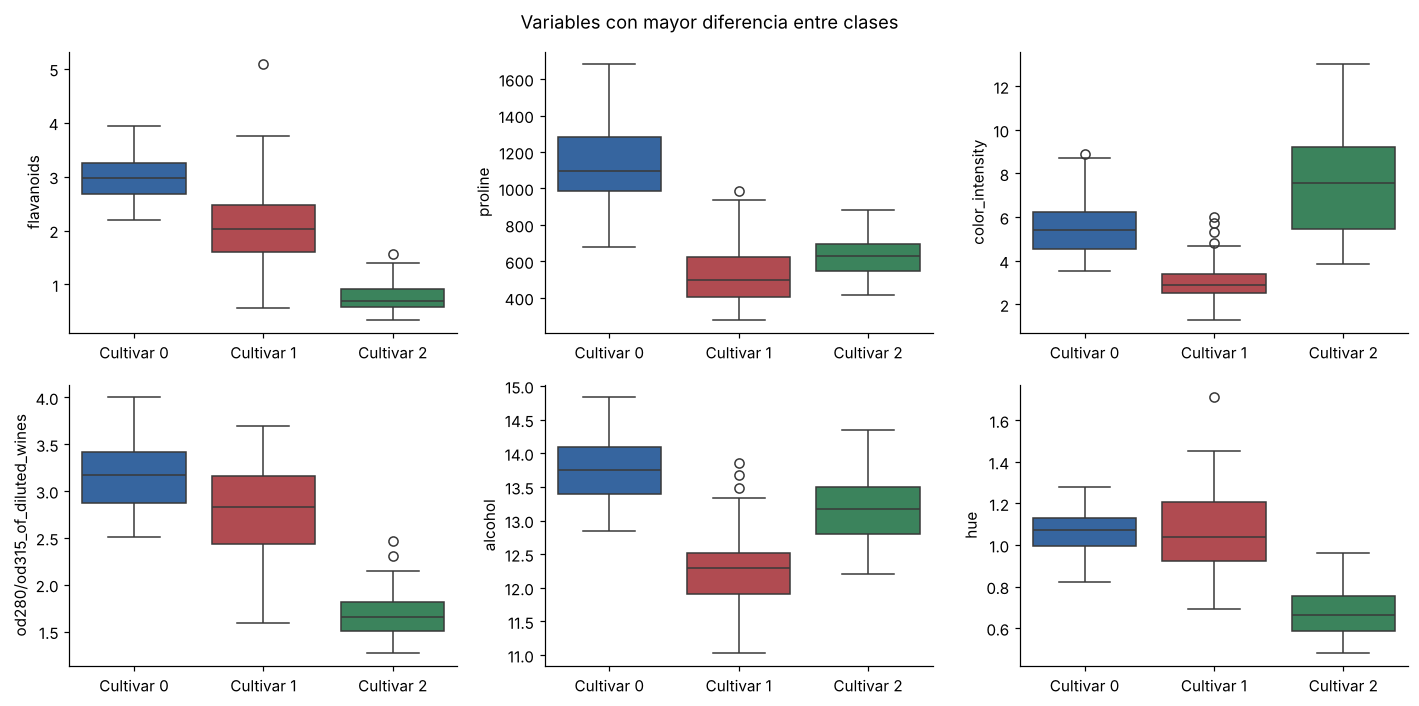

In [8]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, var in zip(ejes.ravel(), ["flavanoids", "proline", "color_intensity",
                                   "od280/od315_of_diluted_wines", "alcohol", "hue"]):
    sns.boxplot(data=df, x=OBJETIVO, y=var, hue=OBJETIVO, palette=COLORES, legend=False, ax=ax)
    ax.set_xticks([0, 1, 2], NOMBRES)
    ax.set_xlabel("")
fig.suptitle("Variables con mayor diferencia entre clases")
guardar("03_boxplots_clases")

### 1.5 Correlaciones y análisis de `QualyScore`

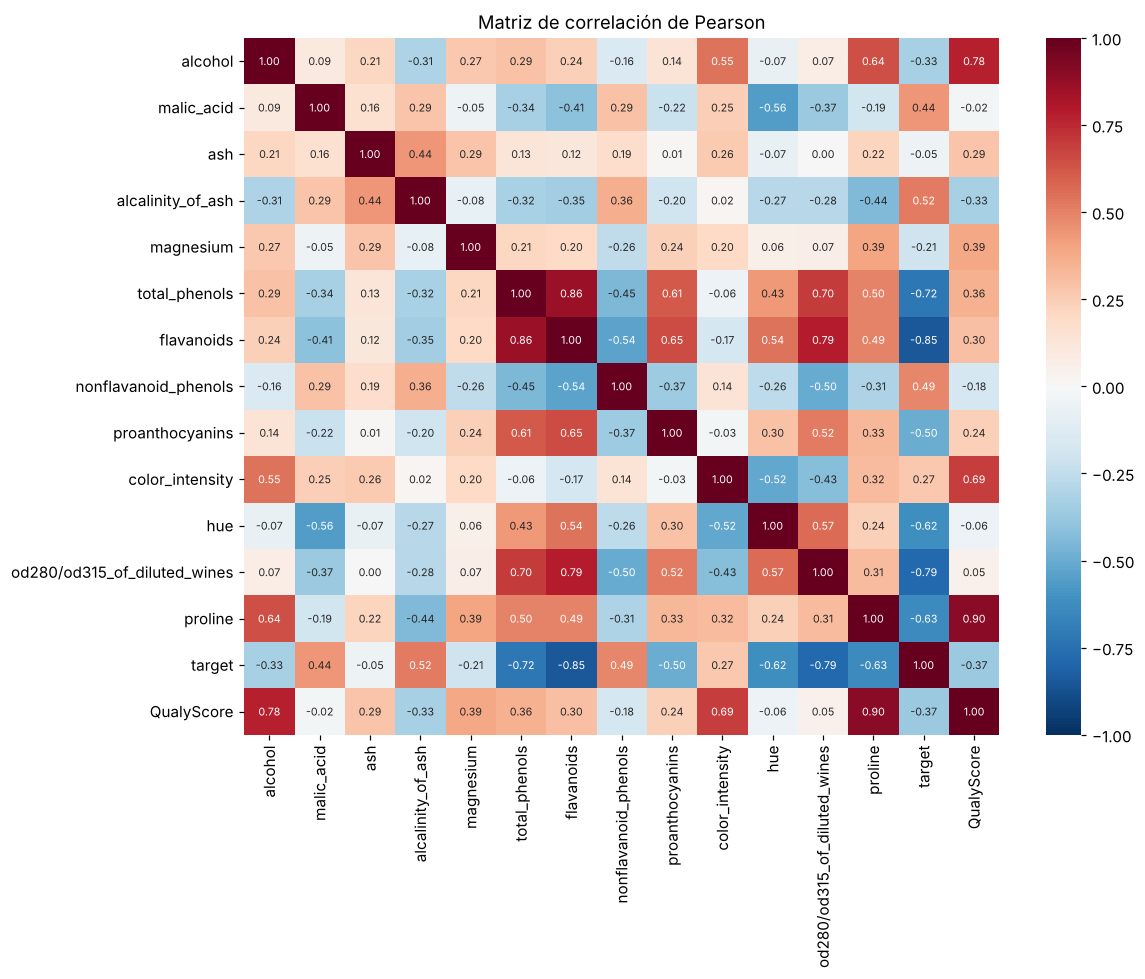

Pares de predictoras más correlacionados:
 total_phenols  flavanoids                      0.865
flavanoids     od280/od315_of_diluted_wines    0.787
total_phenols  od280/od315_of_diluted_wines    0.700
flavanoids     proanthocyanins                 0.653
alcohol        proline                         0.644
dtype: float64


In [9]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Matriz de correlación de Pearson")
guardar("04_correlacion")

pares = (corr.loc[PREDICTORAS, PREDICTORAS].where(np.triu(np.ones((13, 13)), 1).astype(bool))
         .stack().sort_values(key=abs, ascending=False))
print("Pares de predictoras más correlacionados:\n", pares.head(5).round(3))

In [10]:
# ¿QualyScore aporta información nueva o es una combinación de las predictoras?
reg = LinearRegression().fit(df[PREDICTORAS], df["QualyScore"])
r2 = reg.score(df[PREDICTORAS], df["QualyScore"])
coef = pd.Series(reg.coef_, index=PREDICTORAS).round(4)
print(f"R² de QualyScore explicado linealmente por las 13 predictoras: {r2:.6f}")
print("Coeficientes distintos de cero:\n", coef[coef.abs() > 1e-6])
print(f"Intercepto: {reg.intercept_:.2e}")

recalculado = 0.5 * df["alcohol"] + 0.8 * df["color_intensity"] + 0.01 * df["proline"]
print("Error absoluto máximo de la fórmula:", float((recalculado - df["QualyScore"]).abs().max()))
RESULTADOS["qualyscore_r2"] = float(r2)
display(df.groupby(OBJETIVO)["QualyScore"].describe().round(2))

R² de QualyScore explicado linealmente por las 13 predictoras: 1.000000
Coeficientes distintos de cero:
 alcohol            0.50
color_intensity    0.80
proline            0.01
dtype: float64
Intercepto: 1.63e-13
Error absoluto máximo de la fórmula: 3.552713678800501e-15


,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,59.0,22.45,3.01,16.91,19.92,22.28,24.21,30.86
1,71.0,13.80,1.86,10.76,12.46,13.67,15.13,19.02
2,48.0,18.79,2.37,15.01,16.54,18.87,20.49,24.17


## 2. Preparación de los datos
Decisiones (todas se ajustan **solo con el conjunto de entrenamiento** para evitar fuga de información hacia validación y prueba):

| Paso | Decisión | Justificación |
|---|---|---|
| Faltantes | Imputación con la **mediana** (`SimpleImputer`) dentro del flujo | El dataset no tiene faltantes, pero el flujo queda listo para datos nuevos de laboratorio con mediciones incompletas; la mediana es robusta a atípicos. |
| Duplicados | Ninguno que eliminar | Verificado en 1.2. |
| Atípicos | Se **conservan**, tras analizarlos | Se revisan dentro de cada cultivar (Tukey y Mahalanobis), se descartan errores imposibles y se mide con validación cruzada si excluirlos del entrenamiento cambia el desempeño (sección 5.8). |
| Variables categóricas | Predictoras: no hay. Objetivo: **one-hot** (3 columnas) | La salida *softmax* de 3 neuronas y la métrica AUC de Keras requieren el objetivo en formato one-hot. |
| Escalamiento | **Estandarización** (`StandardScaler`, media 0, desv. 1) | Las escalas difieren en tres órdenes de magnitud (prolina ≈ 278–1680 vs. tono ≈ 0.5–1.7). Se comparó empíricamente contra no escalar, normalización 0–1 y logaritmo + estandarización (sección 5.8). |
| Partición | **60 % entrenamiento / 20 % validación / 20 % prueba**, estratificada | La validación explícita y estratificada es más confiable que `validation_split` (que toma las últimas filas sin estratificar). La prueba solo se usa una vez, al final. |

In [11]:
X = df[PREDICTORAS].copy()
y = df[OBJETIVO].values

# Partición estratificada: primero se reserva el 20 % para prueba; del 80 % restante, 25 % es validación (=20 % del total)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEMILLA)

particiones = pd.DataFrame(
    {n: pd.Series(v).value_counts().sort_index().values for n, v in
     [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]}, index=NOMBRES).T
particiones["Total"] = particiones.sum(axis=1)
display(particiones)
RESULTADOS["particiones"] = {k: int(v) for k, v in particiones["Total"].items()}

# Imputación + estandarización ajustadas SOLO con entrenamiento
imputador = SimpleImputer(strategy="median").fit(X_train)
escalador = StandardScaler().fit(imputador.transform(X_train))
preparar = lambda datos: escalador.transform(imputador.transform(datos)).astype("float32")

Xtr, Xva, Xte = preparar(X_train), preparar(X_val), preparar(X_test)

# Codificación one-hot del objetivo
Ytr, Yva, Yte = (keras.utils.to_categorical(v, 3) for v in (y_train, y_val, y_test))

print("Media de entrenamiento tras escalar (≈0):", Xtr.mean(axis=0).round(2)[:5], "...")
print("Desv. estándar tras escalar (≈1):", Xtr.std(axis=0).round(2)[:5], "...")
print("Ejemplo one-hot:", y_train[:3], "->\n", Ytr[:3])

,Cultivar 0,Cultivar 1,Cultivar 2,Total
Entrenamiento,35,43,28,106
Validación,12,14,10,36
Prueba,12,14,10,36


Media de entrenamiento tras escalar (≈0): [ 0. -0.  0.  0.  0.] ...
Desv. estándar tras escalar (≈1): [1. 1. 1. 1. 1.] ...
Ejemplo one-hot: [2 1 2] ->
 [[0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]]


## 3. Diseño del modelo (arquitectura del MLP)
Se define una función que construye el perceptrón multicapa con parámetros variables para poder comparar arquitecturas de forma controlada.

* **Capa de entrada:** 13 neuronas (una por variable química).
* **Capas ocultas:** densas con activación **ReLU** (no lineal, evita el desvanecimiento del gradiente, la misma usada en Metalmex e Iris).
* **Capa de salida:** 3 neuronas con **softmax** → probabilidades que suman 1 (igual que Iris, porque el problema es multiclase; la *sigmoide* de Metalmex solo sirve para 2 clases).
* **Pérdida:** entropía cruzada categórica (`categorical_crossentropy`), equivalente a la `sparse_categorical_crossentropy` de Iris pero con objetivo one-hot.
* **Optimizador:** Adam (tasa de aprendizaje configurable).
* **Regularización opcional:** Dropout y penalización L2, porque con solo 106 vinos de entrenamiento el riesgo de sobreajuste es alto.

In [12]:
N_ENTRADAS = Xtr.shape[1]

def construir_mlp(capas=(8,), dropout=0.0, l2=0.0, lr=1e-3, n_entradas=N_ENTRADAS, nombre="MLP"):
    reg = keras.regularizers.L2(l2) if l2 > 0 else None
    modelo = keras.Sequential(name=nombre)
    modelo.add(keras.Input(shape=(n_entradas,)))
    for i, n in enumerate(capas, 1):
        modelo.add(keras.layers.Dense(n, activation="relu", kernel_regularizer=reg, name=f"oculta_{i}"))
        if dropout > 0:
            modelo.add(keras.layers.Dropout(dropout, name=f"dropout_{i}"))
    modelo.add(keras.layers.Dense(3, activation="softmax", name="salida"))
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="categorical_crossentropy",
                   metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return modelo

def entrenar(config, Xa, Ya, Xv, Yv, semilla=SEMILLA, epocas=300, paciencia=30, early_stopping=True, batch=8):
    keras.utils.set_random_seed(semilla)
    modelo = construir_mlp(**{k: v for k, v in config.items() if k in ("capas", "dropout", "l2", "lr")})
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True)] if early_stopping else []
    h = modelo.fit(Xa, Ya, validation_data=(Xv, Yv), epochs=epocas, batch_size=batch, verbose=0, callbacks=cbs)
    return modelo, h.history

### 3.1 Modelo base (réplica directa de los ejemplos de clase)
Primero se entrena una red con la configuración de los ejemplos (Iris: 1 capa oculta de 8 neuronas, Adam con tasa por defecto, *batch* 8) **sin detención temprana** y durante 300 épocas, para observar el comportamiento sin controles contra el sobreajuste. Este modelo sirve como punto de referencia.

Entrenado en 26.6s


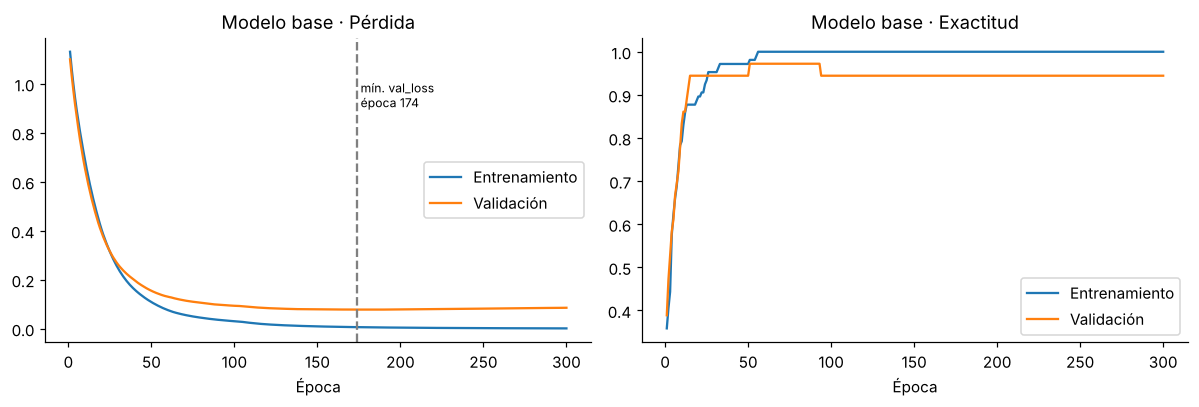

{
  "epoca_min_val_loss": 174,
  "val_loss_min": 0.07806815952062607,
  "val_loss_final": 0.08559678494930267,
  "train_loss_final": 0.0013782648602500558,
  "val_acc_final": 0.9444444179534912,
  "train_acc_final": 1.0
}


In [13]:
base_cfg = dict(capas=(8,), lr=1e-3)
t0 = time.time()
modelo_base, hist_base = entrenar(base_cfg, Xtr, Ytr, Xva, Yva, epocas=300, early_stopping=False)
print(f"Entrenado en {time.time()-t0:.1f}s")

ep = np.arange(1, len(hist_base["loss"]) + 1)
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, k, t in zip(ejes, ("loss", "accuracy"), ("Pérdida", "Exactitud")):
    ax.plot(ep, hist_base[k], label="Entrenamiento")
    ax.plot(ep, hist_base[f"val_{k}"], label="Validación")
    ax.set(xlabel="Época", title=f"Modelo base · {t}"); ax.legend()
mejor = int(np.argmin(hist_base["val_loss"]))
ejes[0].axvline(mejor + 1, ls="--", c="gray"); ejes[0].text(mejor + 3, max(hist_base["loss"]) * .8, f"mín. val_loss\népoca {mejor+1}", fontsize=8)
guardar("05_curvas_modelo_base")

RESULTADOS["base"] = dict(epoca_min_val_loss=mejor + 1, val_loss_min=float(min(hist_base["val_loss"])),
                          val_loss_final=float(hist_base["val_loss"][-1]), train_loss_final=float(hist_base["loss"][-1]),
                          val_acc_final=float(hist_base["val_accuracy"][-1]), train_acc_final=float(hist_base["accuracy"][-1]))
print(json.dumps(RESULTADOS["base"], indent=2))

## 4. Configuración de parámetros y entrenamiento
### 4.1 Búsqueda de arquitectura y tasa de aprendizaje (usando **solo** validación)
Se comparan configuraciones que varían el número de capas, neuronas, regularización y tasa de aprendizaje. Para que la comparación no dependa de una inicialización afortunada, **cada configuración se entrena con 3 semillas** y se promedia.

* Criterio de selección: **menor pérdida de validación promedio** (más sensible que la exactitud, que en 36 vinos cambia en saltos de 2.8 puntos).
* Desempate: el modelo más simple (menos parámetros).
* Parámetros comunes: hasta 300 épocas, EarlyStopping con paciencia 30, *batch* 8.

In [14]:
CONFIGS = {
    "A · [8] (Iris)":                     dict(capas=(8,),      lr=1e-3),
    "B · [26] (regla 2×13)":              dict(capas=(26,),     lr=1e-3),
    "C · [32,16]":                        dict(capas=(32, 16),  lr=1e-3),
    "D · [32,16] + Dropout .3 + L2":      dict(capas=(32, 16),  lr=1e-3, dropout=0.3, l2=1e-3),
    "E · [64,32] + Dropout .3 + L2":      dict(capas=(64, 32),  lr=1e-3, dropout=0.3, l2=1e-3),
    "F · [16,8] + Dropout .2 + L2":       dict(capas=(16, 8),   lr=1e-3, dropout=0.2, l2=1e-3),
    "G · [16,8] + Dropout .2 + L2, lr=0.01":   dict(capas=(16, 8), lr=1e-2, dropout=0.2, l2=1e-3),
    "H · [16,8] + Dropout .2 + L2, lr=0.0001": dict(capas=(16, 8), lr=1e-4, dropout=0.2, l2=1e-3),
}
SEMILLAS = [11, 22, 33]

filas = []
t0 = time.time()
for nombre, cfg in CONFIGS.items():
    for s in SEMILLAS:
        m, h = entrenar(cfg, Xtr, Ytr, Xva, Yva, semilla=s)
        i = int(np.argmin(h["val_loss"]))
        filas.append(dict(config=nombre, semilla=s, parametros=m.count_params(), epocas=len(h["loss"]), mejor_epoca=i + 1,
                          train_loss=h["loss"][i], val_loss=h["val_loss"][i],
                          val_acc=h["val_accuracy"][i], val_auc=h["val_auc"][i]))
print(f"{len(filas)} entrenamientos en {time.time()-t0:.0f}s")

busqueda = pd.DataFrame(filas)
resumen = (busqueda.groupby("config", sort=False)
           .agg(parametros=("parametros", "first"), mejor_epoca=("mejor_epoca", "mean"),
                train_loss=("train_loss", "mean"), val_loss=("val_loss", "mean"), val_loss_sd=("val_loss", "std"),
                val_acc=("val_acc", "mean"), val_auc=("val_auc", "mean"))
           .round(4).sort_values(["val_loss", "parametros"]))
display(resumen)

24 entrenamientos en 421s


,parametros,mejor_epoca,train_loss,val_loss,val_loss_sd,val_acc,val_auc
config,,,,,,,
"C · [32,16]",1027,210.3333,0.0034,0.0300,0.0304,0.9907,0.9999
"G · [16,8] + Dropout .2 + L2, lr=0.01",387,55.6667,0.0567,0.0383,0.0168,0.9907,0.9999
"E · [64,32] + Dropout .3 + L2",3075,209.0000,0.0258,0.0464,0.0036,1.0000,1.0000
B · [26] (regla 2×13),445,182.0000,0.0022,0.0543,0.0095,0.9630,0.9990
"F · [16,8] + Dropout .2 + L2",387,136.3333,0.0989,0.0567,0.0184,1.0000,1.0000
A · [8] (Iris),139,248.6667,0.0028,0.0605,0.0375,0.9815,0.9991
"D · [32,16] + Dropout .3 + L2",1027,90.3333,0.0719,0.0809,0.0525,0.9907,0.9996
"H · [16,8] + Dropout .2 + L2, lr=0.0001",387,300.0000,0.3648,0.2096,0.0314,0.9815,0.9996


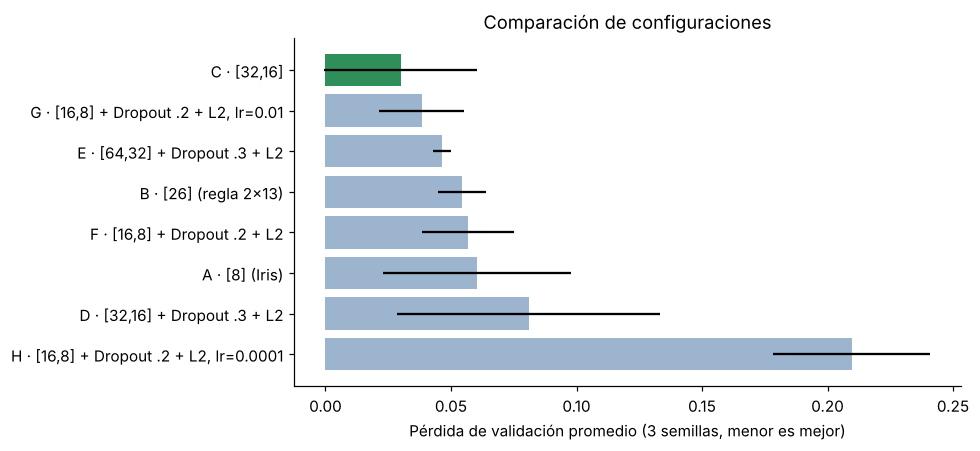

Menor val_loss: C · [32,16]
Configuración seleccionada (más simple dentro de 1 d.e.): G · [16,8] + Dropout .2 + L2, lr=0.01


In [15]:
fig, ax = plt.subplots(figsize=(9, 4.2))
orden = resumen.index[::-1]
ax.barh(orden, resumen.loc[orden, "val_loss"], xerr=resumen.loc[orden, "val_loss_sd"],
        color=["#2F8F5B" if c == resumen.index[0] else "#9DB4CF" for c in orden])
ax.set(xlabel="Pérdida de validación promedio (3 semillas, menor es mejor)", title="Comparación de configuraciones")
guardar("06_busqueda_configuraciones")

# Regla de selección: la de menor val_loss; si otra está a menos de 1 desviación estándar y tiene menos parámetros, se prefiere la más simple
mejor_cfg = resumen.index[0]
umbral = resumen.loc[mejor_cfg, "val_loss"] + resumen.loc[mejor_cfg, "val_loss_sd"]
candidatas = resumen[resumen["val_loss"] <= umbral].sort_values("parametros")
SELECCIONADA = candidatas.index[0]
print("Menor val_loss:", mejor_cfg)
print("Configuración seleccionada (más simple dentro de 1 d.e.):", SELECCIONADA)
CFG_FINAL = CONFIGS[SELECCIONADA]
RESULTADOS["busqueda"] = resumen.reset_index().to_dict(orient="records")
RESULTADOS["config_seleccionada"] = SELECCIONADA

### 4.2 Entrenamiento del modelo final
Se entrena la configuración seleccionada con entrenamiento + monitoreo en validación (EarlyStopping restaura los pesos de la época con menor `val_loss`).

In [16]:
modelo, hist = entrenar(CFG_FINAL, Xtr, Ytr, Xva, Yva, semilla=SEMILLA)
modelo.summary()
mejor_ep = int(np.argmin(hist["val_loss"])) + 1
print(f"Épocas ejecutadas: {len(hist['loss'])} | mejor época (pesos restaurados): {mejor_ep}")
print(f"Actualizaciones de pesos por época: {int(np.ceil(len(Xtr)/8))} lotes de 8 vinos")
RESULTADOS["final"] = dict(config=CFG_FINAL | {"capas": list(CFG_FINAL["capas"])}, parametros=int(modelo.count_params()),
                           epocas=len(hist["loss"]), mejor_epoca=mejor_ep,
                           train_loss=float(hist["loss"][mejor_ep-1]), val_loss=float(hist["val_loss"][mejor_ep-1]),
                           train_acc=float(hist["accuracy"][mejor_ep-1]), val_acc=float(hist["val_accuracy"][mejor_ep-1]),
                           val_auc=float(hist["val_auc"][mejor_ep-1]))
print(json.dumps(RESULTADOS["final"], indent=2))

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,163 (4.55 KB)

 Trainable params: 387 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 776 (3.04 KB)

Épocas ejecutadas: 81 | mejor época (pesos restaurados): 51
Actualizaciones de pesos por época: 14 lotes de 8 vinos
{
  "config": {
    "capas": [
      16,
      8
    ],
    "lr": 0.01,
    "dropout": 0.2,
    "l2": 0.001
  },
  "parametros": 387,
  "epocas": 81,
  "mejor_epoca": 51,
  "train_loss": 0.041991133242845535,
  "val_loss": 0.02950858324766159,
  "train_acc": 1.0,
  "val_acc": 1.0,
  "val_auc": 1.0
}


### 4.3 Evolución del entrenamiento por épocas (modelo final)

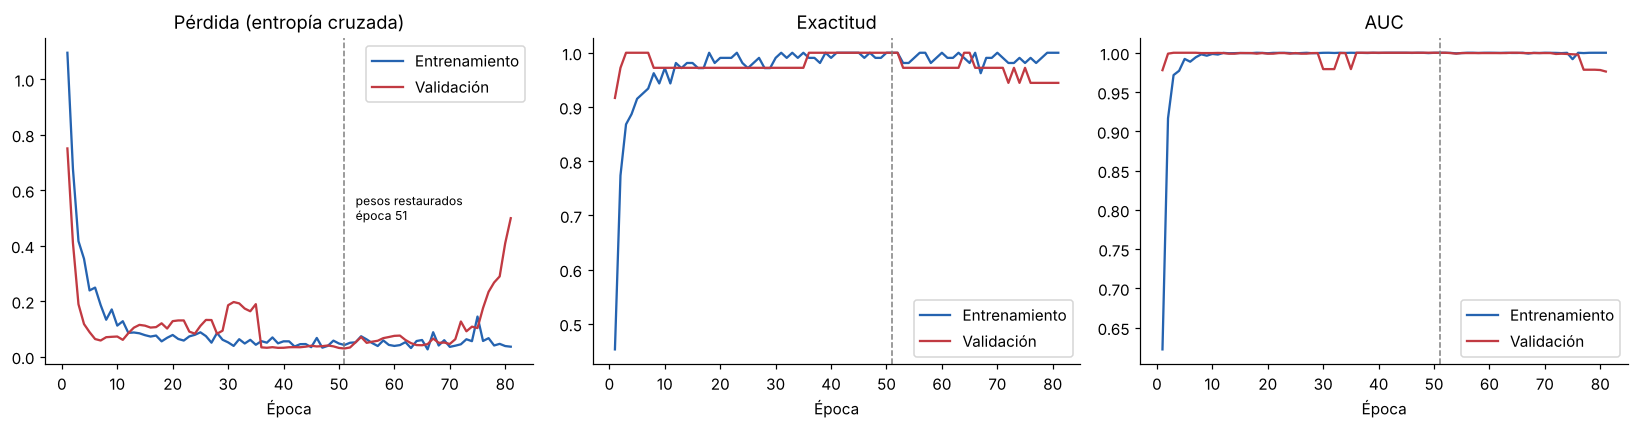

In [17]:
ep = np.arange(1, len(hist["loss"]) + 1)
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k, t in zip(ejes, ("loss", "accuracy", "auc"), ("Pérdida (entropía cruzada)", "Exactitud", "AUC")):
    ax.plot(ep, hist[k], label="Entrenamiento", color="#2563B0")
    ax.plot(ep, hist[f"val_{k}"], label="Validación", color="#C13A42")
    ax.axvline(mejor_ep, ls="--", c="gray", lw=1)
    ax.set(xlabel="Época", title=t); ax.legend()
ejes[0].text(mejor_ep + 2, max(hist["loss"]) * .45, f"pesos restaurados\népoca {mejor_ep}", fontsize=8)
guardar("07_curvas_modelo_final")

## 5. Evaluación del modelo
### 5.1 Desempeño en el conjunto de prueba (36 vinos nunca vistos)
Métricas: **pérdida** (entropía cruzada), **exactitud**, **AUC** (uno-contra-resto, promedio macro), y por clase **precisión, sensibilidad (recall) y F1**.

In [18]:
loss_te, acc_te, auc_keras_te = modelo.evaluate(Xte, Yte, verbose=0)
prob_te = modelo.predict(Xte, verbose=0)
pred_te = prob_te.argmax(axis=1)

auc_ovr = roc_auc_score(y_test, prob_te, multi_class="ovr", average="macro")
f1_macro = f1_score(y_test, pred_te, average="macro")
print(f"Pérdida en prueba:            {loss_te:.4f}")
print(f"Exactitud en prueba:          {acc_te:.2%}  ({int((pred_te==y_test).sum())} de {len(y_test)} vinos)")
print(f"AUC (Keras, micro):           {auc_keras_te:.4f}")
print(f"AUC uno-vs-resto macro:       {auc_ovr:.4f}")
print(f"F1 macro:                     {f1_macro:.4f}\n")
print(classification_report(y_test, pred_te, target_names=NOMBRES, digits=3))

RESULTADOS["prueba"] = dict(loss=float(loss_te), accuracy=float(acc_te), auc_keras=float(auc_keras_te),
                            auc_ovr_macro=float(auc_ovr), f1_macro=float(f1_macro),
                            aciertos=int((pred_te == y_test).sum()), n=int(len(y_test)),
                            reporte=classification_report(y_test, pred_te, target_names=NOMBRES, output_dict=True))

Pérdida en prueba:            0.2538
Exactitud en prueba:          94.44%  (34 de 36 vinos)
AUC (Keras, micro):           0.9778
AUC uno-vs-resto macro:       0.9976
F1 macro:                     0.9429

              precision    recall  f1-score   support

  Cultivar 0      1.000     1.000     1.000        12
  Cultivar 1      0.929     0.929     0.929        14
  Cultivar 2      0.900     0.900     0.900        10

    accuracy                          0.944        36
   macro avg      0.943     0.943     0.943        36
weighted avg      0.944     0.944     0.944        36



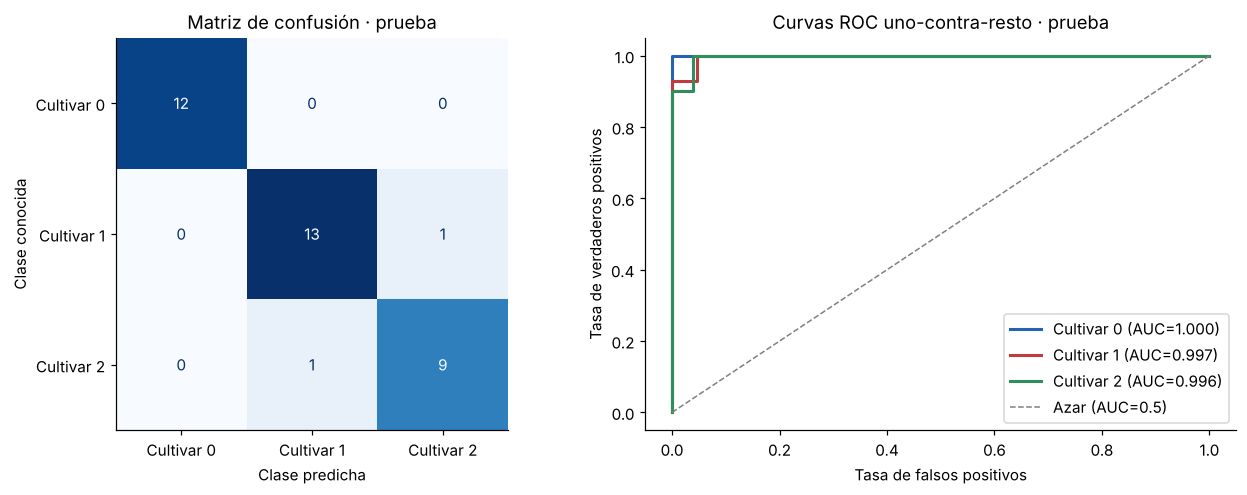

Vinos mal clasificados:


,real,predicha,P(Cultivar 0),P(Cultivar 1),P(Cultivar 2)
4,Cultivar 2,Cultivar 1,0.007,0.769,0.225
16,Cultivar 1,Cultivar 2,0.000,0.001,0.999


Confianza (probabilidad máxima): mediana 1.000, mínimo 0.769
Vinos con confianza < 0.80 (referencia; el umbral se elige en 5.6): 1


In [19]:
cm = confusion_matrix(y_test, pred_te, labels=[0, 1, 2])
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay(cm, display_labels=NOMBRES).plot(cmap="Blues", values_format="d", colorbar=False, ax=ejes[0])
ejes[0].set(title="Matriz de confusión · prueba", xlabel="Clase predicha", ylabel="Clase conocida")

Ybin = label_binarize(y_test, classes=[0, 1, 2])
for k in range(3):
    fpr, tpr, _ = roc_curve(Ybin[:, k], prob_te[:, k])
    ejes[1].plot(fpr, tpr, color=COLORES[k], lw=2, label=f"{NOMBRES[k]} (AUC={roc_auc_score(Ybin[:, k], prob_te[:, k]):.3f})")
ejes[1].plot([0, 1], [0, 1], "--", c="gray", lw=1, label="Azar (AUC=0.5)")
ejes[1].set(title="Curvas ROC uno-contra-resto · prueba", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
ejes[1].legend(loc="lower right")
guardar("08_confusion_roc")
RESULTADOS["matriz_confusion"] = cm.tolist()

# Errores individuales y confianza del modelo
errores = pd.DataFrame(prob_te, columns=[f"P({n})" for n in NOMBRES]).round(3)
errores.insert(0, "real", [NOMBRES[i] for i in y_test]); errores.insert(1, "predicha", [NOMBRES[i] for i in pred_te])
mal = errores[errores.real != errores.predicha]
print("Vinos mal clasificados:" if len(mal) else "No hubo vinos mal clasificados en prueba.")
display(mal)
conf = prob_te.max(axis=1)
print(f"Confianza (probabilidad máxima): mediana {np.median(conf):.3f}, mínimo {conf.min():.3f}")
print("Vinos con confianza < 0.80 (referencia; el umbral se elige en 5.6):", int((conf < 0.80).sum()))
RESULTADOS["confianza"] = dict(mediana=float(np.median(conf)), minimo=float(conf.min()), n_menor_080=int((conf < 0.80).sum()))

### 5.2 Comparación con modelos de referencia
Para saber si la red aporta valor, se compara contra (a) un clasificador ingenuo que siempre predice la clase más frecuente y (b) una **regresión logística multinomial**, el modelo lineal visto en el tema "Modelos lineales de clasificación". Todos usan exactamente los mismos datos preparados.

In [20]:
def metricas(nombre, prob):
    pred = prob.argmax(axis=1)
    return dict(modelo=nombre, exactitud=accuracy_score(y_test, pred), f1_macro=f1_score(y_test, pred, average="macro"),
                auc_ovr=roc_auc_score(y_test, prob, multi_class="ovr"), log_loss=log_loss(y_test, prob, labels=[0, 1, 2]))

dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, y_train)
logit = LogisticRegression(max_iter=2000).fit(Xtr, y_train)
prob_base = modelo_base.predict(Xte, verbose=0)

comparacion = pd.DataFrame([
    metricas("Ingenuo (clase mayoritaria)", dummy.predict_proba(Xte)),
    metricas("Regresión logística", logit.predict_proba(Xte)),
    metricas("MLP base (sin EarlyStopping, 300 épocas)", prob_base),
    metricas(f"MLP final · {SELECCIONADA}", prob_te),
]).set_index("modelo").round(4)
display(comparacion)
RESULTADOS["comparacion"] = comparacion.reset_index().to_dict(orient="records")

# --- Prueba de McNemar: MLP vs regresión logística ---
pred_logit = logit.predict(Xte)
ambos_ok   = int(((pred_te == y_test) & (pred_logit == y_test)).sum())
mlp_ok     = int(((pred_te == y_test) & (pred_logit != y_test)).sum())
logit_ok   = int(((pred_te != y_test) & (pred_logit == y_test)).sum())
ambos_mal  = int(((pred_te != y_test) & (pred_logit != y_test)).sum())
tabla_mc = np.array([[ambos_ok, mlp_ok], [logit_ok, ambos_mal]])
print("Tabla de contingencia McNemar:")
print(f"  Ambos aciertan: {ambos_ok}   Solo MLP acierta: {mlp_ok}")
print(f"  Solo logit acierta: {logit_ok}   Ambos fallan: {ambos_mal}")
# Con valores pequeños se usa la prueba exacta (binomial)
n_discordantes = mlp_ok + logit_ok
if n_discordantes > 0:
    try:
        from scipy.stats import binom_test
        p_value = binom_test(mlp_ok, n_discordantes, 0.5)
    except (ImportError, TypeError):
        from scipy.stats import binomtest
        p_value = binomtest(mlp_ok, n_discordantes, 0.5).pvalue
else:
    p_value = 1.0
print(f"McNemar (exacta): discordantes = {n_discordantes}, p = {p_value:.4f}")
RESULTADOS["mcnemar"] = dict(ambos_ok=ambos_ok, mlp_ok=mlp_ok, logit_ok=logit_ok,
                              ambos_mal=ambos_mal, p_value=float(p_value))

,exactitud,f1_macro,auc_ovr,log_loss
modelo,,,,
Ingenuo (clase mayoritaria),0.3889,0.1867,0.5000,22.0267
Regresión logística,0.9444,0.9452,0.9976,0.1165
"MLP base (sin EarlyStopping, 300 épocas)",0.9444,0.9452,1.0000,0.1092
"MLP final · G · [16,8] + Dropout .2 + L2, lr=0.01",0.9444,0.9429,0.9976,0.2288


Tabla de contingencia McNemar:
  Ambos aciertan: 33   Solo MLP acierta: 1
  Solo logit acierta: 1   Ambos fallan: 1
McNemar (exacta): discordantes = 2, p = 1.0000


### 5.2b Comparación formal: prueba de McNemar (MLP vs. regresión logística)

La tabla de contingencia cuenta los vinos donde los dos modelos discrepan. La prueba de McNemar evalúa si la diferencia es estadísticamente significativa; con pocos discordantes se usa la versión exacta (binomial).

Si *p* > 0.05, **no hay evidencia estadística de que un modelo sea mejor que el otro**, lo que confirma que el MLP no aporta ventaja sobre la regresión logística en este conjunto.

### 5.2c Calibración del modelo

Las probabilidades softmax no están calibradas por construcción: un modelo puede asignar 0.99 de confianza y acertar solo el 80 % de las veces. Para medirlo se usa:
- El **puntaje de Brier** (media de los errores cuadráticos de las probabilidades; 0 = perfecto, máx. = 2 en 3 clases).
- La **curva de calibración** (reliability diagram): se divide el rango de probabilidades en intervalos, se compara la confianza media con la exactitud observada y se calcula el **ECE** (error de calibración esperado, ponderado por la cantidad de predicciones en cada intervalo).

Puntaje de Brier (promedio de las 3 clases): 0.0295
  Cultivar 0: 0.0000
  Cultivar 1: 0.0441
  Cultivar 2: 0.0444


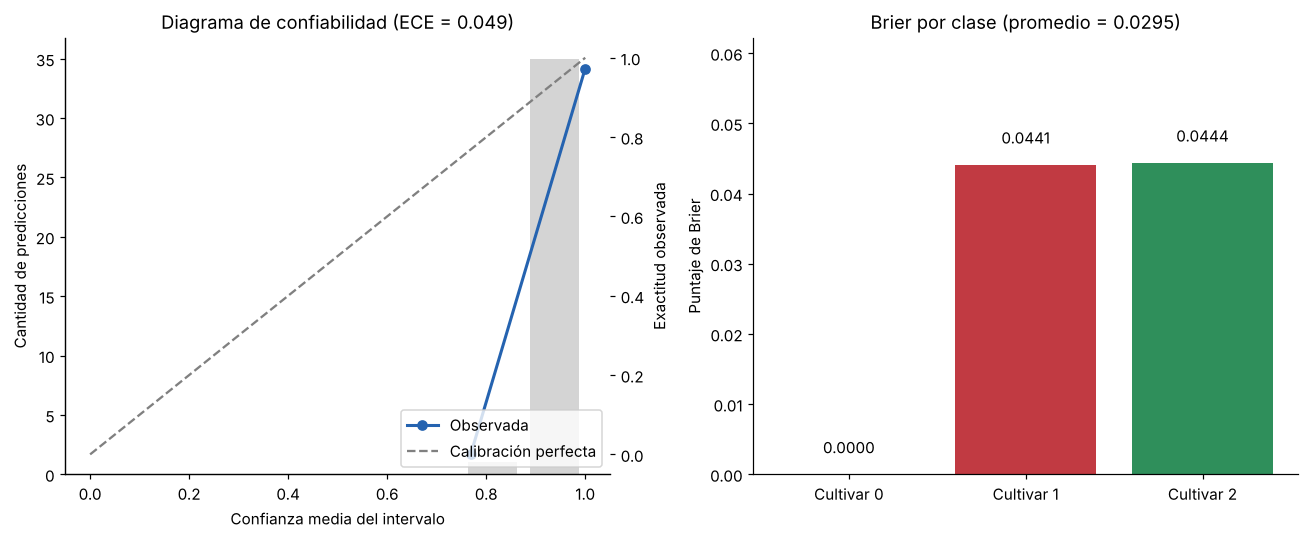

ECE (error de calibración esperado): 0.0487


In [21]:
from sklearn.metrics import brier_score_loss

# Brier multiclase = promedio del Brier por clase (uno contra el resto)
Ybin = keras.utils.to_categorical(y_test, 3)
brier_per_class = [brier_score_loss(Ybin[:, k], prob_te[:, k]) for k in range(3)]
brier_multi = float(np.mean(brier_per_class))
print(f"Puntaje de Brier (promedio de las 3 clases): {brier_multi:.4f}")
for k in range(3):
    print(f"  Cultivar {k}: {brier_per_class[k]:.4f}")

# Curva de calibración (reliability diagram)
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

# Diagrama de confiabilidad agregado (todas las clases juntas)
confianza_todas = prob_te.max(axis=1)
acierto_todas = (pred_te == y_test).astype(float)
n_bins = 8
bins = np.linspace(0, 1, n_bins + 1)
bin_idx = np.digitize(confianza_todas, bins) - 1
bin_idx = np.clip(bin_idx, 0, n_bins - 1)
bin_acc = np.array([acierto_todas[bin_idx == i].mean() if (bin_idx == i).sum() > 0 else np.nan for i in range(n_bins)])
bin_conf = np.array([confianza_todas[bin_idx == i].mean() if (bin_idx == i).sum() > 0 else np.nan for i in range(n_bins)])
bin_count = np.array([(bin_idx == i).sum() for i in range(n_bins)])

# ECE
mask = bin_count > 0
ece = float(np.sum(bin_count[mask] * np.abs(bin_acc[mask] - bin_conf[mask])) / bin_count.sum())

ejes[0].bar((bins[:-1] + bins[1:]) / 2, bin_count, width=1/n_bins * 0.8, color="#aaa", alpha=0.5, label="Vinos por intervalo")
ax2 = ejes[0].twinx()
valid = ~np.isnan(bin_acc)
ax2.plot(bin_conf[valid], bin_acc[valid], "o-", color=COLORES[0], lw=2, label="Observada")
ax2.plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
ejes[0].set(xlabel="Confianza media del intervalo", ylabel="Cantidad de predicciones", title=f"Diagrama de confiabilidad (ECE = {ece:.3f})")
ax2.set_ylabel("Exactitud observada")
ax2.legend(loc="lower right")

# Brier por clase
ejes[1].bar(NOMBRES, brier_per_class, color=COLORES[:3])
ejes[1].set(ylabel="Puntaje de Brier", title=f"Brier por clase (promedio = {brier_multi:.4f})")
ejes[1].set_ylim(0, max(brier_per_class) * 1.4)
for i, v in enumerate(brier_per_class):
    ejes[1].text(i, v + 0.003, f"{v:.4f}", ha="center", fontsize=10)

plt.tight_layout(); guardar("16_calibracion")
RESULTADOS["calibracion"] = dict(brier_multi=brier_multi, brier_por_clase=brier_per_class,
                                  ece=ece, bins_count=bin_count.tolist())
print(f"ECE (error de calibración esperado): {ece:.4f}")

### 5.3 Robustez: validación cruzada estratificada (5 pliegues × 2 repeticiones)
Con solo 36 vinos de prueba, cada error mueve la exactitud ≈2.8 puntos. Para estimar la **variabilidad** del desempeño se repite el entrenamiento de la configuración final con validación cruzada sobre los 142 vinos de desarrollo (entrenamiento + validación). En cada pliegue el escalador se reajusta solo con los datos de entrenamiento de ese pliegue y una parte interna se usa para EarlyStopping. El conjunto de prueba **no** participa.

In [22]:
def cv_mlp(Xdev, ydev, cfg, columnas, repeticiones=2, k=5):
    res = []
    for r in range(repeticiones):
        skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=100 + r)
        for f, (itr, ite) in enumerate(skf.split(Xdev, ydev)):
            Xa, Xb = Xdev.iloc[itr][columnas], Xdev.iloc[ite][columnas]
            ya, yb = ydev[itr], ydev[ite]
            Xa_in, Xa_es, ya_in, ya_es = train_test_split(Xa, ya, test_size=0.2, stratify=ya, random_state=f)
            imp = SimpleImputer(strategy="median").fit(Xa_in); sc = StandardScaler().fit(imp.transform(Xa_in))
            P = lambda d: sc.transform(imp.transform(d)).astype("float32")
            keras.utils.set_random_seed(1000 * r + f)
            m = construir_mlp(**{kk: v for kk, v in cfg.items() if kk in ("capas", "dropout", "l2", "lr")}, n_entradas=len(columnas))
            m.fit(P(Xa_in), keras.utils.to_categorical(ya_in, 3), validation_data=(P(Xa_es), keras.utils.to_categorical(ya_es, 3)),
                  epochs=300, batch_size=8, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)])
            p = m.predict(P(Xb), verbose=0)
            res.append(dict(exactitud=accuracy_score(yb, p.argmax(1)), auc=roc_auc_score(yb, p, multi_class="ovr"),
                            log_loss=log_loss(yb, p, labels=[0, 1, 2])))
    return pd.DataFrame(res)

t0 = time.time()
cv_sin = cv_mlp(X_dev.reset_index(drop=True), y_dev, CFG_FINAL, PREDICTORAS)
print(f"CV terminada en {time.time()-t0:.0f}s")
display(cv_sin.agg(["mean", "std", "min", "max"]).round(4))
RESULTADOS["cv"] = {c: dict(media=float(cv_sin[c].mean()), sd=float(cv_sin[c].std()), min=float(cv_sin[c].min())) for c in cv_sin}

CV terminada en 80s


,exactitud,auc,log_loss
mean,0.9824,0.9981,0.0999
std,0.0251,0.0043,0.1305
min,0.9286,0.9875,0.0009
max,1.0000,1.0000,0.3459


### 5.4 Ajuste justificado: ¿conviene incluir `QualyScore` como predictora?
Se repite la misma validación cruzada agregando `QualyScore` (14 entradas). Si la sección 1.5 es correcta, no debería mejorar el desempeño porque no añade información.

In [23]:
X_dev_q = df.loc[X_dev.index, PREDICTORAS + ["QualyScore"]].reset_index(drop=True)
cv_con = cv_mlp(X_dev_q, y_dev, CFG_FINAL, PREDICTORAS + ["QualyScore"])
tabla_q = pd.DataFrame({"Sin QualyScore (13)": cv_sin.mean(), "Con QualyScore (14)": cv_con.mean()}).T.round(4)
display(tabla_q)
RESULTADOS["cv_con_qualyscore"] = {c: float(cv_con[c].mean()) for c in cv_con}

,exactitud,auc,log_loss
Sin QualyScore (13),0.9824,0.9981,0.0999
Con QualyScore (14),0.9825,0.9987,0.0837


### 5.5 Incertidumbre de las métricas de prueba (bootstrap)
Una exactitud de 94.4 % calculada con 36 vinos es una **estimación puntual**. Para saber qué tan precisa es, se remuestrean con reemplazo los 36 vinos de prueba 2,000 veces y se recalculan las métricas; los percentiles 2.5 y 97.5 dan un **intervalo de confianza del 95 %**. Se reporta también la sensibilidad de cada cultivar, en especial la del **cultivar 2, la clase minoritaria** (27 % de los vinos).

> Nota: que el remuestreo dé estimaciones *estables* no significa que el modelo identifique bien la clase minoritaria; por eso se revisa su sensibilidad por separado.

In [24]:
rng_b = np.random.default_rng(7)
B, filas_b = 2000, []
for _ in range(B):
    idx = rng_b.integers(0, len(y_test), len(y_test))
    yt, pt, pp = y_test[idx], pred_te[idx], prob_te[idx]
    fila = dict(exactitud=accuracy_score(yt, pt), f1_macro=f1_score(yt, pt, average="macro"))
    if len(np.unique(yt)) == 3:
        fila["auc_ovr"] = roc_auc_score(yt, pp, multi_class="ovr")
    for k in range(3):
        if (yt == k).any():
            fila[f"sensibilidad_{k}"] = float((pt[yt == k] == k).mean())
    filas_b.append(fila)
boot = pd.DataFrame(filas_b)
ic = pd.DataFrame({"estimación": {"exactitud": acc_te, "f1_macro": f1_macro, "auc_ovr": auc_ovr,
                                   **{f"sensibilidad_{k}": float((pred_te[y_test == k] == k).mean()) for k in range(3)}},
                   "IC95_inf": boot.quantile(0.025), "IC95_sup": boot.quantile(0.975)}).round(3)
display(ic)
RESULTADOS["bootstrap"] = ic.to_dict(orient="index")

,estimación,IC95_inf,IC95_sup
exactitud,0.944,0.861,1.0
f1_macro,0.943,0.853,1.0
auc_ovr,0.998,0.987,1.0
sensibilidad_0,1.000,1.000,1.0
sensibilidad_1,0.929,0.769,1.0
sensibilidad_2,0.900,0.667,1.0


### 5.6 Umbral de confianza: selección y evaluación en etapas separadas
La propuesta de negocio es **aceptar automáticamente** solo las predicciones con probabilidad máxima ≥ *u* y enviar el resto al enólogo. El umbral *u* **no** se elige mirando la prueba:

1. **Selección (desarrollo, 142 vinos):** con validación cruzada de 5 pliegues se obtienen probabilidades *fuera de pliegue* (cada vino es predicho por un modelo que no lo vio). Para cada umbral candidato se calcula la **cobertura** (% de vinos aceptados automáticamente) y la **exactitud entre los aceptados**. Regla fijada de antemano: el umbral más bajo cuya exactitud entre aceptados sea **≥ 99 %**, dado que un error de etiquetado es más costoso que una revisión manual.
2. **Evaluación (prueba, 36 vinos):** se aplica el umbral elegido una sola vez.

Exactitud fuera de pliegue (desarrollo): 97.2%


,umbral,cobertura,exactitud_aceptados,enviados_revision,errores_capturados,errores_no_capturados
0,0.50,1.000,0.972,0,0,4
1,0.60,1.000,0.972,0,0,4
2,0.70,1.000,0.972,0,0,4
3,0.80,0.986,0.971,2,0,4
4,0.85,0.986,0.971,2,0,4
5,0.90,0.979,0.978,3,1,3
6,0.95,0.958,0.993,6,3,1
7,0.99,0.908,0.992,13,3,1


Umbral seleccionado en desarrollo: 0.95
Evaluación en prueba: {
  "umbral": 0.95,
  "cobertura": 0.9722222222222222,
  "aceptados": 35,
  "enviados_revision": 1,
  "exactitud_aceptados": 0.9714285714285714,
  "errores_capturados": 1,
  "errores_no_capturados": 1
}


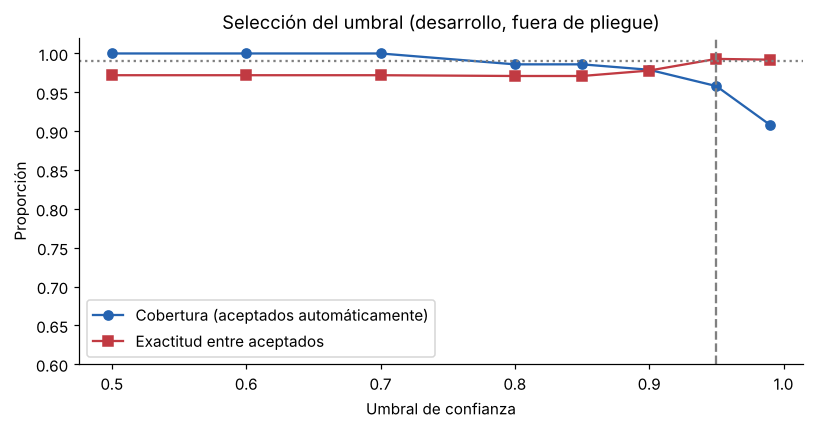

In [25]:
def oof_mlp(Xdev, ydev, cfg, k=5, semilla=500):
    oof = np.zeros((len(ydev), 3))
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=semilla)
    for f, (itr, ite) in enumerate(skf.split(Xdev, ydev)):
        Xa, ya = Xdev.iloc[itr], ydev[itr]
        Xa_in, Xa_es, ya_in, ya_es = train_test_split(Xa, ya, test_size=0.2, stratify=ya, random_state=f)
        imp = SimpleImputer(strategy="median").fit(Xa_in); sc = StandardScaler().fit(imp.transform(Xa_in))
        P = lambda d: sc.transform(imp.transform(d)).astype("float32")
        keras.utils.set_random_seed(semilla + f)
        m = construir_mlp(**{kk: v for kk, v in cfg.items() if kk in ("capas", "dropout", "l2", "lr")})
        m.fit(P(Xa_in), keras.utils.to_categorical(ya_in, 3), validation_data=(P(Xa_es), keras.utils.to_categorical(ya_es, 3)),
              epochs=300, batch_size=8, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)])
        oof[ite] = m.predict(P(Xdev.iloc[ite]), verbose=0)
    return oof

oof = oof_mlp(X_dev.reset_index(drop=True)[PREDICTORAS], y_dev, CFG_FINAL)
conf_oof, ok_oof = oof.max(1), oof.argmax(1) == y_dev
print(f"Exactitud fuera de pliegue (desarrollo): {ok_oof.mean():.1%}")

umbrales = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95, 0.99]
tabla_u = pd.DataFrame([dict(umbral=u, cobertura=(conf_oof >= u).mean(),
                             exactitud_aceptados=ok_oof[conf_oof >= u].mean() if (conf_oof >= u).any() else np.nan,
                             enviados_revision=int((conf_oof < u).sum()),
                             errores_capturados=int((~ok_oof & (conf_oof < u)).sum()),
                             errores_no_capturados=int((~ok_oof & (conf_oof >= u)).sum())) for u in umbrales]).round(3)
display(tabla_u)
validos = tabla_u[tabla_u.exactitud_aceptados >= 0.99]
U = float(validos.umbral.min()) if len(validos) else 0.99
print(f"Umbral seleccionado en desarrollo: {U}")

# Evaluación única en prueba
acept = conf >= U
eval_u = dict(umbral=U, cobertura=float(acept.mean()), aceptados=int(acept.sum()), enviados_revision=int((~acept).sum()),
              exactitud_aceptados=float((pred_te[acept] == y_test[acept]).mean()),
              errores_capturados=int(((pred_te != y_test) & ~acept).sum()),
              errores_no_capturados=int(((pred_te != y_test) & acept).sum()))
print("Evaluación en prueba:", json.dumps(eval_u, indent=2))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(tabla_u.umbral, tabla_u.cobertura, "o-", label="Cobertura (aceptados automáticamente)", color="#2563B0")
ax.plot(tabla_u.umbral, tabla_u.exactitud_aceptados, "s-", label="Exactitud entre aceptados", color="#C13A42")
ax.axhline(0.99, ls=":", c="gray"); ax.axvline(U, ls="--", c="gray")
ax.set(xlabel="Umbral de confianza", ylabel="Proporción", title="Selección del umbral (desarrollo, fuera de pliegue)", ylim=(0.6, 1.02))
ax.legend(loc="lower left")
guardar("12_seleccion_umbral")
RESULTADOS["umbral"] = dict(oof_exactitud=float(ok_oof.mean()), tabla=tabla_u.to_dict(orient="records"), prueba=eval_u)

### 5.7 Incertidumbre de las predicciones individuales (conjunto de 10 redes)
Una sola red da una probabilidad, pero esa probabilidad depende de la inicialización aleatoria. Se entrenan **10 redes con la misma configuración y distintas semillas** y, para cada vino de prueba, se reporta la probabilidad promedio de la clase predicha y su rango entre redes. Un vino cuyo rango es amplio o cuyas redes no coinciden en la clase es un caso **incierto**, aunque una red individual lo clasifique con confianza alta.

,real,predicha_ensamble,p_media,p_min,p_max,acuerdo_redes,pred_red_final,p_red_final,incierto
4,Cultivar 2,Cultivar 2,0.655,0.107,0.973,0.8,Cultivar 1,0.769,True
5,Cultivar 1,Cultivar 1,0.670,0.009,1.000,0.6,Cultivar 1,0.998,True
29,Cultivar 1,Cultivar 1,0.838,0.190,0.999,0.9,Cultivar 1,0.990,True
16,Cultivar 1,Cultivar 2,0.947,0.646,0.999,1.0,Cultivar 2,0.999,True
2,Cultivar 0,Cultivar 0,0.969,0.872,0.999,1.0,Cultivar 0,0.999,True
25,Cultivar 2,Cultivar 2,0.992,0.919,1.000,1.0,Cultivar 2,1.000,True
13,Cultivar 0,Cultivar 0,0.993,0.962,0.999,1.0,Cultivar 0,1.000,False
18,Cultivar 0,Cultivar 0,0.996,0.974,1.000,1.0,Cultivar 0,1.000,False


Exactitud del ensamble: 97.2% | vinos inciertos: 6
Los errores de la red final, ¿están marcados como inciertos por el ensamble? [True, True]


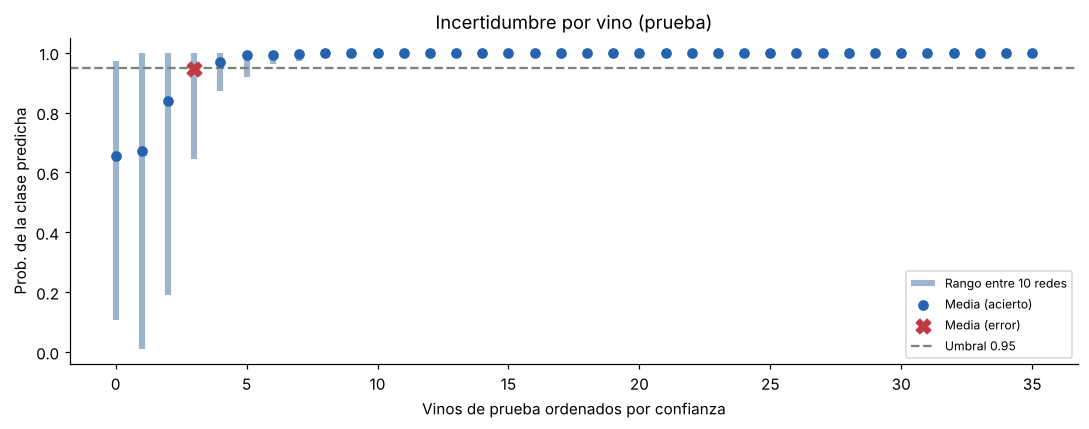

In [26]:
probs_ens = []
for s in range(10):
    m_s, _ = entrenar(CFG_FINAL, Xtr, Ytr, Xva, Yva, semilla=300 + s)
    probs_ens.append(m_s.predict(Xte, verbose=0))
probs_ens = np.stack(probs_ens)                     # (10 redes, 36 vinos, 3 clases)
media = probs_ens.mean(0); clase_ens = media.argmax(1)
p_clase = probs_ens[:, np.arange(len(y_test)), clase_ens]   # prob. de la clase del ensamble en cada red
acuerdo = (probs_ens.argmax(2) == clase_ens).mean(0)        # % de redes que coinciden

inc = pd.DataFrame({"real": [NOMBRES[i] for i in y_test], "predicha_ensamble": [NOMBRES[i] for i in clase_ens],
                    "p_media": p_clase.mean(0), "p_min": p_clase.min(0), "p_max": p_clase.max(0), "acuerdo_redes": acuerdo,
                    "pred_red_final": [NOMBRES[i] for i in pred_te], "p_red_final": conf}).round(3)
inc["incierto"] = (inc.p_min < U) | (inc.acuerdo_redes < 1)
display(inc.sort_values("p_media").head(8))
print(f"Exactitud del ensamble: {(clase_ens == y_test).mean():.1%} | vinos inciertos: {int(inc.incierto.sum())}")
print("Los errores de la red final, ¿están marcados como inciertos por el ensamble?",
      inc.loc[pred_te != y_test, "incierto"].tolist())

orden = np.argsort(p_clase.mean(0))
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(orden))
err = clase_ens[orden] != y_test[orden]
ax.vlines(x, p_clase.min(0)[orden], p_clase.max(0)[orden], color="#9DB4CF", lw=4, label="Rango entre 10 redes")
ax.scatter(x[~err], p_clase.mean(0)[orden][~err], color="#2563B0", zorder=3, label="Media (acierto)")
ax.scatter(x[err], p_clase.mean(0)[orden][err], color="#C13A42", marker="X", s=90, zorder=3, label="Media (error)")
ax.axhline(U, ls="--", c="gray", label=f"Umbral {U}")
ax.set(xlabel="Vinos de prueba ordenados por confianza", ylabel="Prob. de la clase predicha", title="Incertidumbre por vino (prueba)")
ax.legend(fontsize=8, loc="lower right")
guardar("13_incertidumbre_individual")

RESULTADOS["ensamble"] = dict(exactitud=float((clase_ens == y_test).mean()), n_inciertos=int(inc.incierto.sum()),
                              errores=inc[pred_te != y_test].to_dict(orient="records"),
                              mas_inciertos=inc.sort_values("p_media").head(5).to_dict(orient="records"))

### 5.8 Validación empírica de la preparación: valores atípicos y escalamiento
Conservar los atípicos y estandarizar fueron decisiones de la sección 2. Aquí se **analizan** y se **comprueban con datos** en lugar de solo justificarlas en teoría.

**Paso 1 – ¿Hay valores imposibles?** Todas las mediciones químicas deben ser positivas y estar en rangos enológicos razonables.

In [27]:
print("¿Todas las mediciones son > 0?", bool((df[PREDICTORAS] > 0).all().all()))
display(df[PREDICTORAS].agg(["min", "max"]).T.round(2))

¿Todas las mediciones son > 0? True


,min,max
alcohol,11.03,14.83
malic_acid,0.74,5.80
ash,1.36,3.23
alcalinity_of_ash,10.60,30.00
magnesium,70.00,162.00
total_phenols,0.98,3.88
flavanoids,0.34,5.08
nonflavanoid_phenols,0.13,0.66
proanthocyanins,0.41,3.58
color_intensity,1.28,13.00


**Paso 2 – Atípicos univariados: globales vs. dentro de cada cultivar.** La regla de Tukey aplicada a los 178 vinos mezclados puede marcar como "atípico" un valor que es normal para su cultivar (y al revés). Por eso se repite dentro de cada clase.

In [28]:
def tukey(d):
    q1, q3 = d.quantile(.25), d.quantile(.75); r = q3 - q1
    return (d < q1 - 1.5 * r) | (d > q3 + 1.5 * r)

at_global = tukey(df[PREDICTORAS])
at_clase = pd.concat([tukey(df.loc[df[OBJETIVO] == k, PREDICTORAS]) for k in range(3)]).loc[df.index]
comp = pd.DataFrame({"global": at_global.sum(), "dentro de su cultivar": at_clase.sum()})
display(comp[comp.sum(axis=1) > 0])
print(f"Global: {int(at_global.sum().sum())} valores en {int(at_global.any(axis=1).sum())} vinos | "
      f"Por cultivar: {int(at_clase.sum().sum())} valores en {int(at_clase.any(axis=1).sum())} vinos")
print("Atípicos globales que son normales dentro de su cultivar:", int((at_global & ~at_clase).sum().sum()))
print("Vinos atípicos en ≥ 2 variables dentro de su cultivar:", int((at_clase.sum(axis=1) >= 2).sum()))

,global,dentro de su cultivar
alcohol,0,3
malic_acid,3,16
ash,3,3
alcalinity_of_ash,4,7
magnesium,4,5
total_phenols,0,4
flavanoids,0,2
nonflavanoid_phenols,0,5
proanthocyanins,2,14
color_intensity,4,5


Global: 21 valores en 17 vinos | Por cultivar: 68 valores en 49 vinos
Atípicos globales que son normales dentro de su cultivar: 6
Vinos atípicos en ≥ 2 variables dentro de su cultivar: 13


**Paso 3 – Atípicos multivariados (distancia de Mahalanobis por cultivar).** Un vino puede ser normal en cada variable por separado pero raro en su combinación. Se calcula la distancia de Mahalanobis² de cada vino al centro de su cultivar y se marca si supera el percentil 97.5 de una χ² con 13 grados de libertad. También se probó la versión robusta (MCD), pero con ~50 vinos por clase y 13 variables marca a más de un tercio de los vinos, lo que no es creíble: la covarianza robusta es inestable con tan pocos datos.

Se consideran **candidatos a atípico** los vinos con Mahalanobis alta **o** atípicos en dos o más variables dentro de su cultivar.

Mahalanobis clásica > χ²(0.975, 13) = 24.7: 5 vinos | versión robusta MCD: 62 vinos (inestable)
Candidatos a atípico (unión de criterios): 14 vinos -> {0: 3, 1: 9, 2: 2}


,cultivar,Mahalanobis²,variables atípicas en su cultivar
13,0,25.1,"alcalinity_of_ash, nonflavanoid_phenols, proan..."
73,1,27.7,"alcalinity_of_ash, magnesium, proline"
96,1,25.1,magnesium
110,1,25.2,"malic_acid, proanthocyanins"
121,1,39.5,"ash, alcalinity_of_ash, flavanoids, color_inte..."


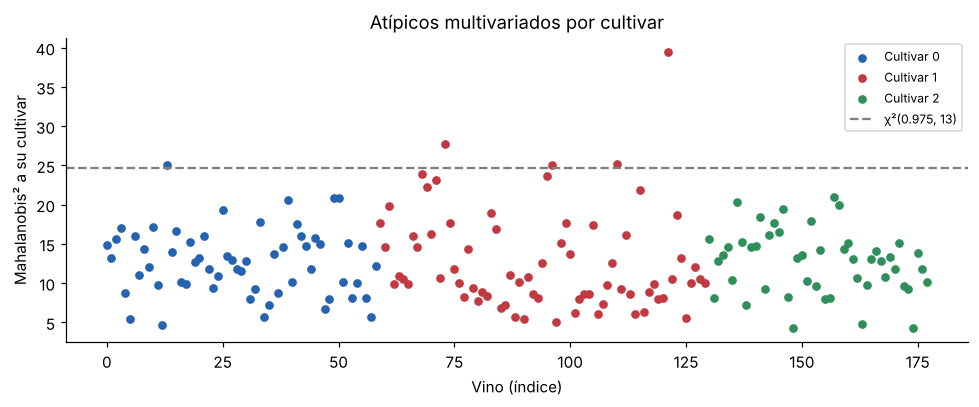

In [29]:
from scipy.stats import chi2
from sklearn.covariance import MinCovDet
LIM_CHI2 = chi2.ppf(0.975, len(PREDICTORAS))

def mahalanobis_por_clase(X, y):
    d = np.zeros(len(y))
    for k in np.unique(y):
        s = y == k
        Z = StandardScaler().fit_transform(X[s])
        d[s] = np.einsum("ij,jk,ik->i", Z, np.linalg.pinv(np.cov(Z.T)), Z)
    return d

def candidatos_atipicos(Xdf, y):
    # Mahalanobis alta o >= 2 atípicos univariados dentro de su clase
    X = Xdf[PREDICTORAS].values
    tk = pd.concat([tukey(Xdf.loc[y == k, PREDICTORAS]) for k in np.unique(y)]).loc[Xdf.index]
    return (mahalanobis_por_clase(X, y) > LIM_CHI2) | (tk.sum(axis=1).values >= 2)

d2 = mahalanobis_por_clase(df[PREDICTORAS].values, df[OBJETIVO].values)
mcd = sum(int((MinCovDet(random_state=0).fit(StandardScaler().fit_transform(df.loc[df[OBJETIVO] == k, PREDICTORAS]))
               .mahalanobis(StandardScaler().fit_transform(df.loc[df[OBJETIVO] == k, PREDICTORAS])) > LIM_CHI2).sum()) for k in range(3))
cand = candidatos_atipicos(df, df[OBJETIVO].values)
print(f"Mahalanobis clásica > χ²(0.975, 13) = {LIM_CHI2:.1f}: {int((d2 > LIM_CHI2).sum())} vinos | versión robusta MCD: {mcd} vinos (inestable)")
print(f"Candidatos a atípico (unión de criterios): {int(cand.sum())} vinos ->", pd.Series(df.loc[cand, OBJETIVO]).value_counts().sort_index().to_dict())
tabla_at = pd.DataFrame({"cultivar": df.loc[d2 > LIM_CHI2, OBJETIVO], "Mahalanobis²": d2[d2 > LIM_CHI2].round(1),
                         "variables atípicas en su cultivar": [", ".join(at_clase.columns[at_clase.loc[i]]) for i in df.index[d2 > LIM_CHI2]]})
display(tabla_at)

fig, ax = plt.subplots(figsize=(9, 3.8))
for k in range(3):
    s = (df[OBJETIVO] == k).values
    ax.scatter(np.where(s)[0], d2[s], c=COLORES[k], s=22, label=NOMBRES[k])
ax.axhline(LIM_CHI2, ls="--", c="gray", label="χ²(0.975, 13)")
ax.set(xlabel="Vino (índice)", ylabel="Mahalanobis² a su cultivar", title="Atípicos multivariados por cultivar")
ax.legend(fontsize=8)
guardar("14_mahalanobis")
RESULTADOS["atipicos"] = dict(global_valores=int(at_global.sum().sum()), global_vinos=int(at_global.any(axis=1).sum()),
                              clase_valores=int(at_clase.sum().sum()), clase_vinos=int(at_clase.any(axis=1).sum()),
                              globales_normales_en_clase=int((at_global & ~at_clase).sum().sum()),
                              vinos_2mas=int((at_clase.sum(axis=1) >= 2).sum()), mahalanobis=int((d2 > LIM_CHI2).sum()),
                              mcd=mcd, candidatos=int(cand.sum()), lim=float(LIM_CHI2),
                              tabla=tabla_at.reset_index().to_dict(orient="records"))

**Paso 4 – ¿Importan para el modelo? (análisis de sensibilidad).** La pregunta correcta no es si hay atípicos, sino si **cambian el desempeño**. Con la misma validación cruzada de la sección 5.3 (5 pliegues × 2 repeticiones sobre los 142 vinos de desarrollo) se comparan:

* **Atípicos:** entrenar con todos los vinos vs. **excluir del entrenamiento** los candidatos a atípico (detectados solo con los datos de entrenamiento de cada pliegue). La evaluación siempre se hace con **todos** los vinos del pliegue de validación, porque en la operación real también llegarán vinos atípicos.
* **Escalamiento:** sin escalar, estandarización, normalización 0–1 (`MinMaxScaler`) y logaritmo en las 4 variables más asimétricas (magnesio, ácido málico, intensidad de color y prolina; asimetría de 0.77 a 1.10) seguido de estandarización.

Todos los ajustes (imputación, escalamiento y detección de atípicos) se hacen **dentro** de cada pliegue para evitar fuga de información.

Asimetría: {'magnesium': 1.1, 'malic_acid': 1.04, 'color_intensity': 0.87, 'proline': 0.77, 'proanthocyanins': 0.52}


50 entrenamientos en 432s


,exactitud,exactitud_sd,auc,log_loss,log_loss_sd,epocas,excluidos_por_pliegue
escenario,,,,,,,
"Estandarización, con atípicos (modelo final)",0.9824,0.0251,0.9981,0.0999,0.1305,93.8,0.0
"Estandarización, sin atípicos en entrenamiento",0.9647,0.0238,0.9975,0.1225,0.1176,101.2,6.3
Sin escalar,0.4851,0.1292,0.6574,0.9637,0.1672,89.9,0.0
Normalización 0–1,0.9719,0.0277,0.9983,0.0867,0.0947,130.8,0.0
Log en 4 variables + estandarización,0.9860,0.0181,0.9995,0.0709,0.0893,90.2,0.0


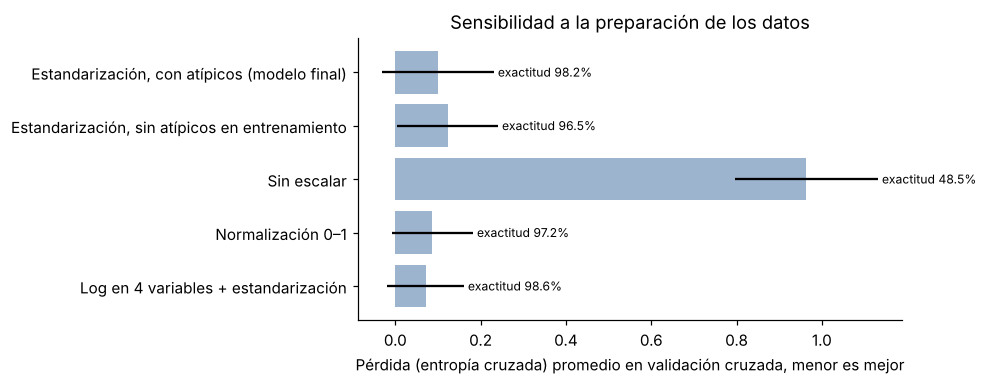

In [30]:
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
SESGADAS = ["magnesium", "malic_acid", "color_intensity", "proline"]
print("Asimetría:", df[PREDICTORAS].skew().round(2).sort_values(ascending=False).head(5).to_dict())

def preprocesador(tipo):
    imp = SimpleImputer(strategy="median")
    if tipo == "sin escalar":        return make_pipeline(imp)
    if tipo == "estandarización":    return make_pipeline(imp, StandardScaler())
    if tipo == "normalización 0–1":  return make_pipeline(imp, MinMaxScaler())
    if tipo == "log + estandarización":
        idx = [PREDICTORAS.index(c) for c in SESGADAS]
        def log_sesgadas(A):
            A = np.array(A, dtype=float).copy(); A[:, idx] = np.log1p(A[:, idx]); return A
        return make_pipeline(imp, FunctionTransformer(log_sesgadas), StandardScaler())

def cv_prep(Xdev, ydev, cfg, tipo="estandarización", excluir=False, repeticiones=2, k=5):
    res = []
    for r in range(repeticiones):
        skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=100 + r)
        for f, (itr, ite) in enumerate(skf.split(Xdev, ydev)):
            Xa, ya = Xdev.iloc[itr], ydev[itr]
            n_ex = 0
            if excluir:
                m = candidatos_atipicos(Xa, ya); n_ex = int(m.sum())
                Xa, ya = Xa[~m], ya[~m]
            Xa_in, Xa_es, ya_in, ya_es = train_test_split(Xa, ya, test_size=0.2, stratify=ya, random_state=f)
            pre = preprocesador(tipo).fit(Xa_in[PREDICTORAS])
            Pp = lambda d: pre.transform(d[PREDICTORAS]).astype("float32")
            keras.utils.set_random_seed(1000 * r + f)
            m_ = construir_mlp(**{kk: v for kk, v in cfg.items() if kk in ("capas", "dropout", "l2", "lr")})
            h = m_.fit(Pp(Xa_in), keras.utils.to_categorical(ya_in, 3), validation_data=(Pp(Xa_es), keras.utils.to_categorical(ya_es, 3)),
                       epochs=300, batch_size=8, verbose=0,
                       callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)])
            p = m_.predict(Pp(Xdev.iloc[ite]), verbose=0)
            res.append(dict(exactitud=accuracy_score(ydev[ite], p.argmax(1)), auc=roc_auc_score(ydev[ite], p, multi_class="ovr"),
                            log_loss=log_loss(ydev[ite], p, labels=[0, 1, 2]), epocas=len(h.history["loss"]), excluidos=n_ex))
    return pd.DataFrame(res)

Xd = X_dev.reset_index(drop=True)
t0 = time.time()
escenarios = {"Estandarización, con atípicos (modelo final)": ("estandarización", False),
              "Estandarización, sin atípicos en entrenamiento": ("estandarización", True),
              "Sin escalar": ("sin escalar", False),
              "Normalización 0–1": ("normalización 0–1", False),
              "Log en 4 variables + estandarización": ("log + estandarización", False)}
filas_s = []
for nombre, (tipo, exc) in escenarios.items():
    rcv = cv_prep(Xd, y_dev, CFG_FINAL, tipo=tipo, excluir=exc)
    filas_s.append(dict(escenario=nombre, exactitud=rcv.exactitud.mean(), exactitud_sd=rcv.exactitud.std(),
                        auc=rcv.auc.mean(), log_loss=rcv.log_loss.mean(), log_loss_sd=rcv.log_loss.std(),
                        epocas=rcv.epocas.mean(), excluidos_por_pliegue=rcv.excluidos.mean()))
print(f"{len(escenarios) * 10} entrenamientos en {time.time() - t0:.0f}s")
sens = pd.DataFrame(filas_s).set_index("escenario").round(4)
display(sens)
RESULTADOS["sensibilidad_prep"] = sens.reset_index().to_dict(orient="records")

fig, ax = plt.subplots(figsize=(9, 3.6))
orden = sens.index[::-1]
ax.barh(orden, sens.loc[orden, "log_loss"], xerr=sens.loc[orden, "log_loss_sd"], color="#9DB4CF")
for i, e in enumerate(orden):
    ax.text(sens.loc[e, "log_loss"] + sens.loc[e, "log_loss_sd"] + 0.01, i, f"exactitud {sens.loc[e, 'exactitud']:.1%}", va="center", fontsize=8)
ax.set(xlabel="Pérdida (entropía cruzada) promedio en validación cruzada, menor es mejor", title="Sensibilidad a la preparación de los datos")
guardar("15_sensibilidad_preparacion")

**Cómo leer esta tabla.** Si excluir los atípicos del entrenamiento no mejora el desempeño de forma clara (diferencias dentro de la variación entre pliegues), conservarlos queda justificado **con evidencia**: no perjudican al modelo y eliminarlos solo reduciría la información. Del mismo modo, la comparación de escalamientos muestra si la estandarización era necesaria y si una transformación logarítmica aporta algo.

## 6. Visualización de lo que aprendió la red (PCA)
### 6.1 Espacio original vs. espacio aprendido por la capa oculta
* **Izquierda:** PCA de las 13 variables estandarizadas (lo que "ve" la red a la entrada).
* **Derecha:** PCA de las **activaciones de la última capa oculta** (la representación interna que la red construyó). Si la red aprendió características útiles, las clases deben verse más compactas y separadas en este espacio.

Se usan todos los vinos (entrenamiento ○, validación △, prueba ★) para ver la estructura completa; el PCA se ajusta solo con entrenamiento.

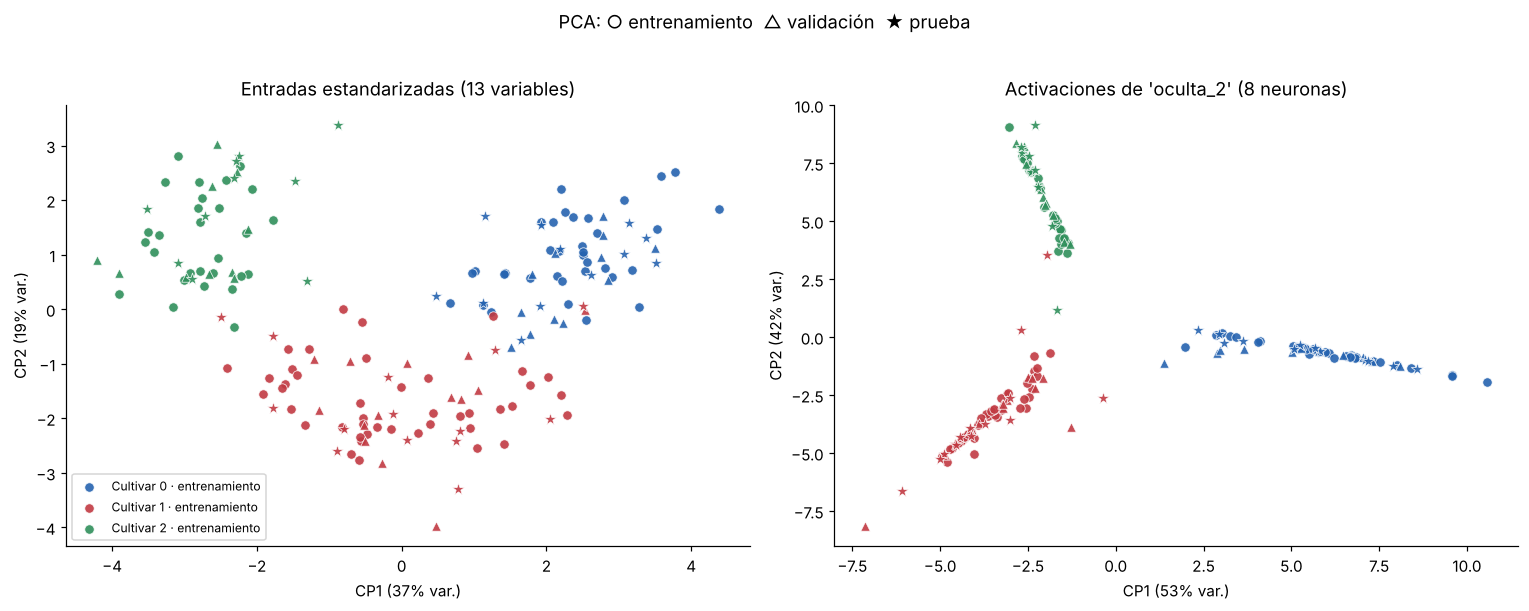

Varianza explicada 2 CP · entrada: 55.2% | oculta: 94.2%
Silueta de las clases (prueba) · espacio de entrada: 0.444 | espacio aprendido: 0.676


In [31]:
pca_in = PCA(n_components=2).fit(Xtr)
capa_oculta = [l for l in modelo.layers if l.name.startswith("oculta_")][-1]
extractor = keras.Model(inputs=modelo.inputs, outputs=capa_oculta.output)
H_tr = extractor.predict(Xtr, verbose=0)
pca_h = PCA(n_components=2).fit(H_tr)

conjuntos = [(Xtr, y_train, "o", "entrenamiento"), (Xva, y_val, "^", "validación"), (Xte, y_test, "*", "prueba")]
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, transformar, titulo, pca in [
        (ejes[0], lambda d: pca_in.transform(d), "Entradas estandarizadas (13 variables)", pca_in),
        (ejes[1], lambda d: pca_h.transform(extractor.predict(d, verbose=0)), f"Activaciones de '{capa_oculta.name}' ({capa_oculta.units} neuronas)", pca_h)]:
    for datos, clases, marca, etiqueta in conjuntos:
        Z = transformar(datos)
        for k in range(3):
            s = clases == k
            ax.scatter(Z[s, 0], Z[s, 1], c=COLORES[k], marker=marca, s=70 if marca == "*" else 38, edgecolor="white", lw=.5,
                       label=f"{NOMBRES[k]} · {etiqueta}" if etiqueta == "entrenamiento" else None, alpha=.9)
    v = pca.explained_variance_ratio_
    ax.set(title=titulo, xlabel=f"CP1 ({v[0]:.0%} var.)", ylabel=f"CP2 ({v[1]:.0%} var.)")
ejes[0].legend(fontsize=8, loc="best")
fig.suptitle("PCA: ○ entrenamiento  △ validación  ★ prueba", y=1.02)
guardar("09_pca_entrada_vs_oculta")

from sklearn.metrics import silhouette_score
sil_in = silhouette_score(pca_in.transform(Xte), y_test)
sil_h = silhouette_score(pca_h.transform(extractor.predict(Xte, verbose=0)), y_test)
print(f"Varianza explicada 2 CP · entrada: {pca_in.explained_variance_ratio_.sum():.1%} | oculta: {pca_h.explained_variance_ratio_.sum():.1%}")
print(f"Silueta de las clases (prueba) · espacio de entrada: {sil_in:.3f} | espacio aprendido: {sil_h:.3f}")
RESULTADOS["pca"] = dict(var_entrada=float(pca_in.explained_variance_ratio_.sum()), var_oculta=float(pca_h.explained_variance_ratio_.sum()),
                         var_entrada_cp=pca_in.explained_variance_ratio_.tolist(),
                         silueta_entrada=float(sil_in), silueta_oculta=float(sil_h))

### 6.2 Fronteras de decisión proyectadas en el plano PCA
Como en Metalmex, el fondo indica la clase que predice la red y los puntos la clase conocida (prueba). Como la red usa 13 dimensiones, cada punto del plano se reconstruye en 13D con `pca.inverse_transform` (las demás componentes se fijan en su media); es una **aproximación visual**, no la frontera exacta.

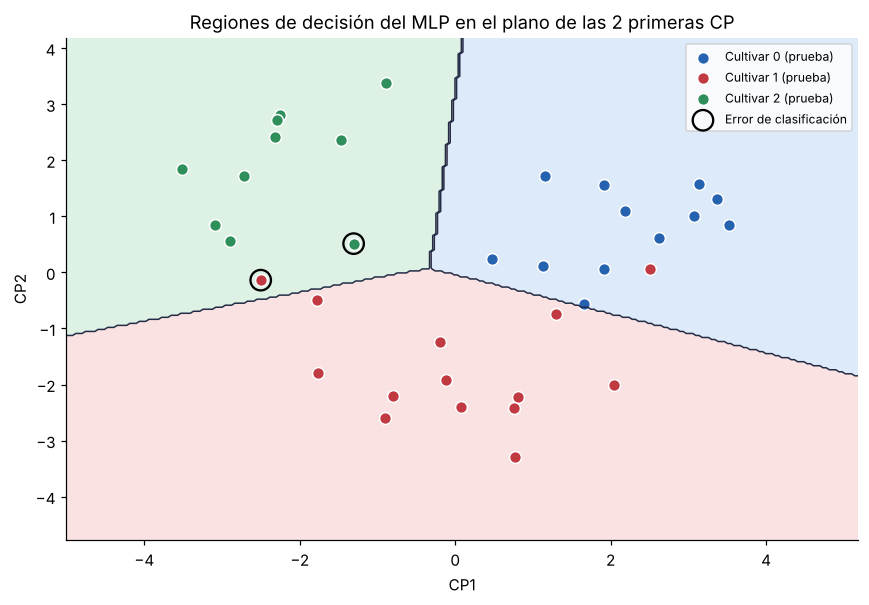

In [32]:
Zall = pca_in.transform(np.vstack([Xtr, Xva, Xte]))
gx = np.linspace(Zall[:, 0].min() - .8, Zall[:, 0].max() + .8, 250)
gy = np.linspace(Zall[:, 1].min() - .8, Zall[:, 1].max() + .8, 250)
xx, yy = np.meshgrid(gx, gy)
malla = pca_in.inverse_transform(np.c_[xx.ravel(), yy.ravel()]).astype("float32")
P_malla = modelo.predict(malla, batch_size=2048, verbose=0)
zona = P_malla.argmax(1).reshape(xx.shape); confianza = P_malla.max(1).reshape(xx.shape)

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.contourf(xx, yy, zona, levels=[-.5, .5, 1.5, 2.5], cmap=ListedColormap(["#DDEAF9", "#FAE1E2", "#DDF2E5"]))
ax.contour(xx, yy, zona, levels=[.5, 1.5], colors="#242C45", linewidths=1)
Zte = pca_in.transform(Xte)
for k in range(3):
    s = y_test == k
    ax.scatter(Zte[s, 0], Zte[s, 1], c=COLORES[k], edgecolor="white", s=60, label=f"{NOMBRES[k]} (prueba)")
err = pred_te != y_test
ax.scatter(Zte[err, 0], Zte[err, 1], facecolor="none", edgecolor="black", s=180, lw=1.5, label="Error de clasificación")
ax.set(title="Regiones de decisión del MLP en el plano de las 2 primeras CP", xlabel="CP1", ylabel="CP2")
ax.legend(fontsize=8)
guardar("10_frontera_pca")

### 6.3 ¿Qué variables usa más la red? (importancia por permutación)
Se desordena aleatoriamente una variable a la vez en el conjunto de prueba (30 repeticiones) y se mide cuánto **aumenta la pérdida**. Un aumento grande significa que la red depende de esa variable. Esto ayuda a interpretar una red neuronal, que por sí sola es una "caja negra".

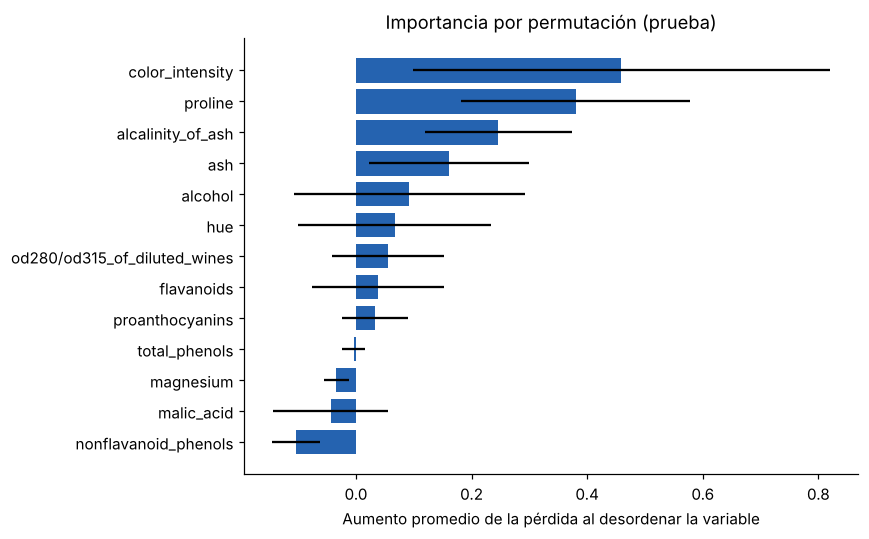

,aumento_logloss,sd
color_intensity,0.4591,0.3612
proline,0.3800,0.1986
alcalinity_of_ash,0.2462,0.1274
ash,0.1608,0.1380
alcohol,0.0922,0.1996
hue,0.0667,0.1672
od280/od315_of_diluted_wines,0.0554,0.0974
flavanoids,0.0377,0.1145
proanthocyanins,0.0327,0.0569
total_phenols,-0.0037,0.0200


In [33]:
rng = np.random.default_rng(SEMILLA)
base_ll = log_loss(y_test, prob_te, labels=[0, 1, 2])
imp = {}
for j, var in enumerate(PREDICTORAS):
    aumentos = []
    for _ in range(30):
        Xp = Xte.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
        aumentos.append(log_loss(y_test, modelo.predict(Xp, verbose=0), labels=[0, 1, 2]) - base_ll)
    imp[var] = (np.mean(aumentos), np.std(aumentos))
imp = pd.DataFrame(imp, index=["aumento_logloss", "sd"]).T.sort_values("aumento_logloss")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.aumento_logloss, xerr=imp.sd, color="#2563B0")
ax.set(title="Importancia por permutación (prueba)", xlabel="Aumento promedio de la pérdida al desordenar la variable")
guardar("11_importancia_permutacion")
display(imp.sort_values("aumento_logloss", ascending=False).round(4))
RESULTADOS["importancia"] = imp.sort_values("aumento_logloss", ascending=False)["aumento_logloss"].round(4).to_dict()

## 7. Uso del modelo: predicción para vinos nuevos
Igual que en Metalmex, las muestras nuevas deben tener **las mismas 13 variables, en el mismo orden y pasar por la misma imputación y estandarización** ajustadas en entrenamiento. Se construyen tres perfiles de ejemplo: los vinos típicos (mediana) de los cultivares 0 y 2, y un perfil intermedio entre los cultivares 1 y 2 (caso ambiguo).

In [34]:
med = X_train.groupby(y_train).median()
nuevos = pd.DataFrame([med.loc[0], med.loc[2], (med.loc[1] + med.loc[2]) / 2],
                      index=["Vino A (perfil típico cultivar 0)", "Vino B (perfil típico cultivar 2)", "Vino C (perfil intermedio 1-2)"])
nuevos.loc["Vino D (con un dato faltante)"] = med.loc[1]
nuevos.loc["Vino D (con un dato faltante)", "magnesium"] = np.nan   # demuestra la imputación
display(nuevos.round(2))

p_nuevos = modelo.predict(preparar(nuevos), verbose=0)
salida = pd.DataFrame(p_nuevos, index=nuevos.index, columns=[f"P({n})" for n in NOMBRES]).round(3)
salida["Predicción"] = [NOMBRES[i] for i in p_nuevos.argmax(1)]
salida["Acción sugerida"] = np.where(p_nuevos.max(1) >= U, "Aceptar etiqueta sugerida", "Enviar a revisión del enólogo")
display(salida)
RESULTADOS["nuevos"] = salida.reset_index().to_dict(orient="records")

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
Vino A (perfil típico cultivar 0),13.76,1.77,2.48,17.00,107.00,2.80,2.92,0.29,1.92,5.60,1.07,3.00,1185.0
Vino B (perfil típico cultivar 2),13.10,3.26,2.46,21.50,96.50,1.55,0.60,0.48,1.00,6.86,0.70,1.74,600.0
Vino C (perfil intermedio 1-2),12.63,2.47,2.37,20.75,92.25,1.88,1.31,0.42,1.31,4.90,0.86,2.27,540.0
Vino D (con un dato faltante),12.17,1.67,2.28,20.00,NaN,2.20,2.01,0.37,1.62,2.95,1.02,2.81,480.0


,P(Cultivar 0),P(Cultivar 1),P(Cultivar 2),Predicción,Acción sugerida
Vino A (perfil típico cultivar 0),1.000,0.00,0.000,Cultivar 0,Aceptar etiqueta sugerida
Vino B (perfil típico cultivar 2),0.000,0.00,1.000,Cultivar 2,Aceptar etiqueta sugerida
Vino C (perfil intermedio 1-2),0.005,0.79,0.205,Cultivar 1,Enviar a revisión del enólogo
Vino D (con un dato faltante),0.000,1.00,0.000,Cultivar 1,Aceptar etiqueta sugerida


## 8. Conclusiones (resumen de cifras de esta corrida)

In [35]:
r = RESULTADOS
print(f"Configuración final: {r['config_seleccionada']} | parámetros entrenables: {r['final']['parametros']}")
print(f"Prueba: exactitud {r['prueba']['accuracy']:.1%} ({r['prueba']['aciertos']}/{r['prueba']['n']}), "
      f"pérdida {r['prueba']['loss']:.3f}, AUC OvR {r['prueba']['auc_ovr_macro']:.3f}, F1 macro {r['prueba']['f1_macro']:.3f}")
print(f"Validación cruzada (10 entrenamientos): exactitud {r['cv']['exactitud']['media']:.1%} ± {r['cv']['exactitud']['sd']:.1%}, "
      f"AUC {r['cv']['auc']['media']:.3f} ± {r['cv']['auc']['sd']:.3f}")
print("Variables más influyentes:", list(r["importancia"])[:4])

with open("resultados_vinianalytics.json", "w", encoding="utf-8") as f:
    json.dump(RESULTADOS, f, ensure_ascii=False, indent=2, default=float)
modelo.save("mlp_vinianalytics.keras")
print("Guardados: resultados_vinianalytics.json, mlp_vinianalytics.keras y figuras en figs/")

Configuración final: G · [16,8] + Dropout .2 + L2, lr=0.01 | parámetros entrenables: 387
Prueba: exactitud 94.4% (34/36), pérdida 0.254, AUC OvR 0.998, F1 macro 0.943
Validación cruzada (10 entrenamientos): exactitud 98.2% ± 2.5%, AUC 0.998 ± 0.004
Variables más influyentes: ['color_intensity', 'proline', 'alcalinity_of_ash', 'ash']


Guardados: resultados_vinianalytics.json, mlp_vinianalytics.keras y figuras en figs/
